# Evaluating historical residual correction and learned reliability for cost-sensitive early regional wheat yield forecasting

This notebook reproduces all results, tables and figures of the study. It uses CY-Bench wheat records, evaluates ten forecasting configurations (C1–C5 and B1–B4b) in a chronological design at three forecast cutoffs, and compares them with point, interval and cost-sensitive decision metrics.

**Requirements:** a Kaggle notebook with a GPU accelerator and the CY-Bench wheat folders attached as input (`wheat/<country>/<kind>_wheat_<country>.csv`). Run all cells in order.

| Section | Content |
|---|---|
| 0 | Independent country screening (K-means and silhouette score) |
| 1–2 | Environment, data loading and date-limited features |
| 3–4 | Rolling models, historical tuning and the main experiment (C1–C5) |
| 5–6 | Main tables, figures, audit and sensitivity checks |
| 6b–6c | Baselines B1–B4b, extended inference and cost-ratio sweep |
| 7–8 | Reproducibility snapshot, run report and export |
| 9 | Supplementary MAE-difference figures |

## 0. Independent country screening

The 29 CY-Bench wheat countries are screened by region–year records, historical years and administrative regions. K-means clustering with $k \in \{2,\dots,6\}$ is selected by the silhouette score, and the data-rich group defines the countries used in the forecasting experiment. No model accuracy or forecast result enters this step.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import json

CANDIDATE_ROOTS = [
    Path('/kaggle/input/datasets/wakeupsahitya/cybench-wheat'),
    Path('/kaggle/input/cybench-wheat'),
]
RAW_ROOT = next((p for p in CANDIDATE_ROOTS if (p/'wheat').is_dir()), None)
if RAW_ROOT is None:
    raise FileNotFoundError('CY-Bench directory not found. Update CANDIDATE_ROOTS to contain wheat/<country>/yield_wheat_<country>.csv')
COUNTRY_DIR = RAW_ROOT/'wheat'
OUT = Path('/kaggle/working/independent_country_eda')
OUT.mkdir(parents=True, exist_ok=True)
COUNTRIES = sorted(p.name for p in COUNTRY_DIR.iterdir() if p.is_dir())
print('Raw root:',RAW_ROOT)
print('Countries found:',len(COUNTRIES),COUNTRIES)


Raw root: /kaggle/input/datasets/wakeupsahitya/cybench-wheat
Countries found: 29 ['AR', 'AT', 'AU', 'BE', 'BG', 'BR', 'CN', 'CZ', 'DE', 'DK', 'EE', 'EL', 'ES', 'FI', 'FR', 'HR', 'HU', 'IE', 'IN', 'IT', 'LT', 'LV', 'NL', 'PL', 'PT', 'RO', 'SE', 'SK', 'US']


In [2]:
def pick(columns, exact, contains=()):
    low={str(c).lower():c for c in columns}
    for s in exact:
        if s in low: return low[s]
    for c in columns:
        if any(s in str(c).lower() for s in contains): return c
    return None

def audit_country(co):
    base=COUNTRY_DIR/co
    yield_path=base/f'yield_wheat_{co}.csv'
    if not yield_path.exists():
        return dict(country=co, status='no yield file')
    y=pd.read_csv(yield_path)
    adm=pick(y.columns,['adm_id'],['adm','region'])
    yr=pick(y.columns,['harvest_year','year'],['harvest_year'])
    target=pick(y.columns,['yield'],['yield'])
    if not all([adm,yr,target]):
        return dict(country=co,status='yield schema missing',missing_schema=str([adm,yr,target]))
    original=len(y)
    y=y[[adm,yr,target]].copy()
    y.columns=['adm_id','year','yield']
    y['year']=pd.to_numeric(y['year'],errors='coerce')
    y['yield']=pd.to_numeric(y['yield'],errors='coerce')
    y=y.dropna(subset=['adm_id','year','yield'])
    y=y[(y['yield']>0)&(y['year'].between(1800,2100))]
    y['year']=y['year'].astype(int)
    unique=y[['adm_id','year']].drop_duplicates()
    n=len(unique); years=unique.year.nunique(); regions=unique.adm_id.nunique()
    year_span=unique.year.max()-unique.year.min()+1 if n else np.nan
    calendar_path=base/f'crop_calendar_wheat_{co}.csv'
    coverage=np.nan
    if calendar_path.exists() and n:
        cal=pd.read_csv(calendar_path)
        ca=pick(cal.columns,['adm_id'],['adm','region'])
        if ca:
            cal_ids=set(cal[ca].dropna().unique().tolist())
            coverage=unique.adm_id.isin(cal_ids).mean()
    kinds=['meteo','soil_moisture','fpar','ndvi','soil']
    present={f'has_{k}':int((base/f'{k}_wheat_{co}.csv').exists()) for k in kinds}
    return dict(country=co,status='ok',raw_rows=original,
        valid_rows=len(y),unique_pairs=n,years=years,regions=regions,
        first_year=int(unique.year.min()) if n else np.nan,
        last_year=int(unique.year.max()) if n else np.nan,
        year_continuity=years/year_span if n else np.nan,
        pair_density=n/(years*regions) if n else np.nan,
        duplicate_region_year=len(y)-n,
        calendar_region_coverage=coverage,**present)

report=pd.DataFrame([audit_country(c) for c in COUNTRIES]).sort_values('country')
report.to_csv(OUT/'01_all_29_raw_audit.csv',index=False)
print(report[['country','status','unique_pairs','years','regions','year_continuity','pair_density','calendar_region_coverage']].to_string(index=False))


country status  unique_pairs  years  regions  year_continuity  pair_density  calendar_region_coverage
     AR     ok         12660     55      380         1.000000      0.605742                  0.974803
     AT     ok           171     26        9         1.000000      0.730769                  1.000000
     AU     ok           740     35       27         1.000000      0.783069                  0.998649
     BE     ok           216     21       11         1.000000      0.935065                  1.000000
     BG     ok            46     11        6         0.478261      0.696970                  1.000000
     BR     ok         39209     49     1579         1.000000      0.506766                  0.999949
     CN     ok           821     33       30         1.000000      0.829293                  1.000000
     CZ     ok           294     21       14         1.000000      1.000000                  1.000000
     DE     ok         15233     43      397         1.000000      0.892332       

In [3]:
eligible=report[(report.status=='ok') & (report[['unique_pairs','years','regions']]>0).all(axis=1)].copy().reset_index(drop=True)
metrics=['unique_pairs','years','regions']
X=StandardScaler().fit_transform(np.log1p(eligible[metrics]))
candidates=[]
for k in range(2,min(6,len(eligible)-1)+1):
    labels=KMeans(n_clusters=k,n_init=50,random_state=42).fit_predict(X)
    candidates.append({'k':k,'silhouette':silhouette_score(X,labels)})
quality=pd.DataFrame(candidates)
best_k=int(quality.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]['k'])
labels=KMeans(n_clusters=best_k,n_init=50,random_state=42).fit_predict(X)
eligible['cluster']=labels
cluster_summary=eligible.groupby('cluster')[metrics].median().sort_values('unique_pairs',ascending=False)
selected_cluster=cluster_summary.index[0]
eligible['screened_data_rich']=eligible.cluster.eq(selected_cluster)
eligible=eligible.sort_values(['screened_data_rich','unique_pairs'],ascending=[False,False])
eligible.to_csv(OUT/'02_screening_results_all_countries.csv',index=False)
quality.to_csv(OUT/'03_cluster_quality.csv',index=False)
cluster_summary.to_csv(OUT/'04_cluster_profiles.csv')
selected=eligible.loc[eligible.screened_data_rich,'country'].tolist()
print('Silhouette diagnostics:\n',quality.to_string(index=False))
print('Chosen k:',best_k)
print('Country cluster medians:\n',cluster_summary.to_string())
print('INDEPENDENT SCREENED DATA-RICH COUNTRIES (n=%d):'%len(selected),selected)
print('Additional source-file issues for screened countries:')
print(eligible.loc[eligible.screened_data_rich,['country','calendar_region_coverage','year_continuity','pair_density','has_meteo','has_soil_moisture','has_fpar','has_ndvi','has_soil']].to_string(index=False))


Silhouette diagnostics:
  k  silhouette
 2    0.558785
 3    0.501395
 4    0.454352
 5    0.450432
 6    0.411788
Chosen k: 2
Country cluster medians:
          unique_pairs  years  regions
cluster                              
1             12660.0   34.0    397.0
0               216.0   21.0     11.5
INDEPENDENT SCREENED DATA-RICH COUNTRIES (n=7): ['US', 'BR', 'DE', 'AR', 'IN', 'FR', 'IT']
Additional source-file issues for screened countries:
country  calendar_region_coverage  year_continuity  pair_density  has_meteo  has_soil_moisture  has_fpar  has_ndvi  has_soil
     US                  0.997132              1.0      0.592399          1                  1         1         1         1
     BR                  0.999949              1.0      0.506766          1                  1         1         1         1
     DE                  1.000000              1.0      0.892332          1                  1         1         1         1
     AR                  0.974803              1.0

In [4]:
def cluster_screen(data, cols):
    z=StandardScaler().fit_transform(np.log1p(data[cols]))
    opts=[]
    for k in range(2,min(6,len(data)-1)+1):
        lab=KMeans(n_clusters=k,random_state=42,n_init=50).fit_predict(z)
        opts.append((silhouette_score(z,lab),-k,k,lab))
    _,_,k,lab=max(opts,key=lambda x:(x[0],x[1]))
    tmp=data.copy();tmp['lab']=lab
    top=tmp.groupby('lab').unique_pairs.median().idxmax()
    return k,set(tmp.loc[tmp.lab==top,'country'])

checks=[]; base=set(selected)
for removed in metrics:
    cols=[x for x in metrics if x!=removed]
    kk,sc=cluster_screen(eligible,cols)
    checks.append({'omitted_metric':removed,'k':kk,'selected_count':len(sc),
                   'jaccard_vs_full':len(base&sc)/len(base|sc),
                   'selected_countries':','.join(sorted(sc))})
stability=pd.DataFrame(checks)
stability.to_csv(OUT/'05_leave_one_metric_out.csv',index=False)
print(stability.to_string(index=False))


omitted_metric  k  selected_count  jaccard_vs_full   selected_countries
  unique_pairs  3               7         1.000000 AR,BR,DE,FR,IN,IT,US
         years  2               7         1.000000 AR,BR,DE,FR,IN,IT,US
       regions  3               6         0.857143    AR,BR,DE,FR,IN,US


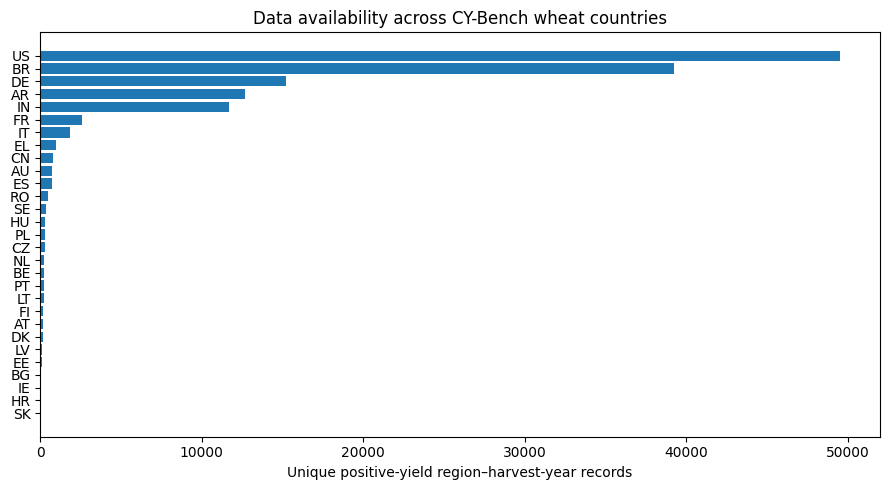

Files saved to /kaggle/working/independent_country_eda


In [5]:
fig,ax=plt.subplots(figsize=(9,5))
sorted_data=eligible.sort_values('unique_pairs',ascending=True)
ax.barh(sorted_data.country,sorted_data.unique_pairs)
ax.set_xlabel('Unique positive-yield region–harvest-year records')
ax.set_title('Data availability across CY-Bench wheat countries')
fig.tight_layout()
fig.savefig(OUT/'06_country_data_volume.png',dpi=180)
plt.show()
with open(OUT/'screening_manifest.json','w') as f:
    json.dump({'selection_method':'silhouette-chosen kmeans of standardized log1p raw yield region-year records, years, regions',
       'chosen_clusters':best_k,'number_of_countries':len(COUNTRIES),
       'selected_count':len(selected),'selected_countries':selected,
       'excluded_from_model_selection':['manuscript countries','model accuracy','effect sizes','forecast cutoffs','target number of countries']},f,indent=2)
print('Files saved to',OUT)


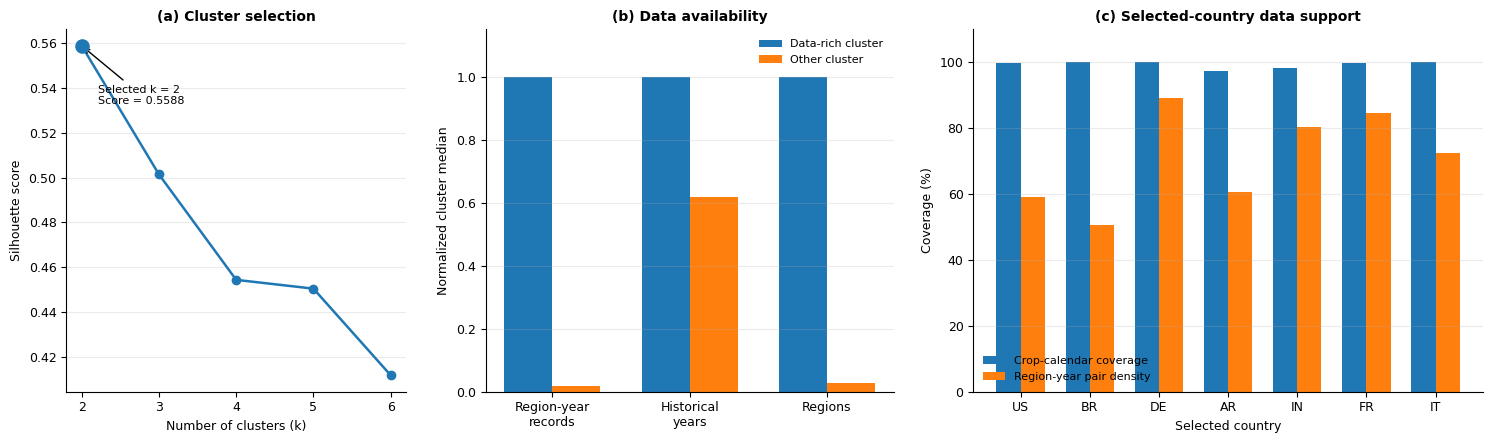

Selected countries: ['US', 'BR', 'DE', 'AR', 'IN', 'FR', 'IT']
Selected k: 2
Silhouette score: 0.558785
Figure saved to: /kaggle/working/independent_country_eda/figures


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
FIG_DIR = Path(OUT) / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600
})

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5),
    gridspec_kw={"width_ratios": [1, 1.2, 1.5]}
)

# (a) Silhouette score
ax = axes[0]

q = quality.sort_values("k")

ax.plot(
    q["k"], q["silhouette"],
    marker="o", linewidth=1.8
)

best_score = q.loc[q["k"] == best_k, "silhouette"].iloc[0]

ax.scatter(
    [best_k], [best_score],
    s=90, zorder=4
)

ax.annotate(
    f"Selected k = {best_k}\nScore = {best_score:.4f}",
    xy=(best_k, best_score),
    xytext=(12, -42),
    textcoords="offset points",
    fontsize=8,
    arrowprops={"arrowstyle": "->"}
)

ax.set_xticks(q["k"])
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title("(a) Cluster selection", fontweight="bold")
ax.grid(axis="y", alpha=0.25)

# (b) Cluster characteristics
ax = axes[1]

profile = cluster_summary.copy()

# Normalize each variable for visual comparison
normalized = profile[metrics].div(
    profile[metrics].max(axis=0)
)

x = np.arange(len(metrics))
width = 0.35

for idx, cluster in enumerate(normalized.index):
    values = normalized.loc[cluster, metrics].to_numpy()

    label = (
        "Data-rich cluster"
        if cluster == selected_cluster
        else "Other cluster"
    )

    ax.bar(
        x + (idx - (len(normalized) - 1) / 2) * width,
        values,
        width,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(
    ["Region-year\nrecords", "Historical\nyears", "Regions"]
)

ax.set_ylim(0, 1.15)
ax.set_ylabel("Normalized cluster median")
ax.set_title("(b) Data availability", fontweight="bold")
ax.legend(fontsize=8, frameon=False)
ax.grid(axis="y", alpha=0.25)

# (c) Data completeness of selected countries
ax = axes[2]

screened = eligible.loc[
    eligible["screened_data_rich"]
].copy()

screened = screened.sort_values("unique_pairs", ascending=False)

countries = screened["country"].tolist()
x = np.arange(len(countries))
width = 0.35

calendar = (
    screened["calendar_region_coverage"].astype(float).to_numpy()
    * 100
)

density = (
    screened["pair_density"].astype(float).to_numpy()
    * 100
)

ax.bar(
    x - width / 2,
    calendar,
    width,
    label="Crop-calendar coverage"
)

ax.bar(
    x + width / 2,
    density,
    width,
    label="Region-year pair density"
)

ax.set_xticks(x)
ax.set_xticklabels(countries)
ax.set_ylim(0, 110)
ax.set_ylabel("Coverage (%)")
ax.set_xlabel("Selected country")
ax.set_title("(c) Selected-country data support",
             fontweight="bold")
ax.legend(fontsize=8, frameon=False, loc="lower left")
ax.grid(axis="y", alpha=0.25)

# Figure formatting
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout(w_pad=2.2)

# Export
base = FIG_DIR / "Fig_S_independent_country_screening"

for ext in ["pdf", "png", "svg"]:
    fig.savefig(
        f"{base}.{ext}",
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

print("Selected countries:", countries)
print("Selected k:", best_k)
print("Silhouette score:", round(best_score, 6))
print("Figure saved to:", FIG_DIR)


---
## Forecasting experiment

Sections 1–8 use only the countries selected in Section 0. Every outer test season uses earlier seasons alone for model fitting, tuning and historical residuals.

## 1. Environment and data

Checks the software stack and GPU, sets the random seed (42) and locates the CY-Bench wheat input folders.

In [7]:
# Keep Kaggle's installed scientific stack; repair only incompatible/missing packages.
# If this cell changes packages, restart the Kaggle session and run all cells again.
import sys, subprocess
from importlib import metadata

def installed(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

repairs = []
np_v = installed('numpy')
if np_v is None:
    repairs.append('numpy>=2.0,<3')
for package, requirement in [('xgboost', 'xgboost>=2.0,<4'),
                             ('scikit-learn', 'scikit-learn>=1.4,<2'),
                             ('scipy', 'scipy>=1.13,<2'),
                             ('statsmodels', 'statsmodels>=0.14,<1'),
                             ('pandas', 'pandas>=2.2,<3'),
                             ('pyarrow', 'pyarrow>=15,<24')]:
    if installed(package) is None:
        repairs.append(requirement)
if repairs:
    print('Repairing only:', repairs)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', *repairs])
    raise RuntimeError('Packages updated. RESTART the Kaggle session, then Run All from the beginning.')
print('Using preinstalled Kaggle package versions; no forced downgrade or reinstall.')

Using preinstalled Kaggle package versions; no forced downgrade or reinstall.


In [8]:
import os, sys, json, time, hashlib, random, platform, subprocess
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, f1_score, precision_recall_fscore_support, log_loss
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from IPython.display import display

# Keep the working Kaggle environment; record versions.
actual = {'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
          'sklearn':sklearn.__version__,'xgboost':xgb.__version__}
from packaging.version import Version
assert Version(actual['numpy']) >= Version('1.26'), actual
assert Version(actual['xgboost']) >= Version('2.0'), 'XGBoost 2+ required for device=cuda.'
print('Verified software environment:', actual)

SEED = 42  # reproducibility protocol, not a tuned scientific parameter
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED)
try:
    gpu = subprocess.check_output(['nvidia-smi','-L'], text=True, timeout=10).strip()
except Exception as e:
    raise RuntimeError('Enable a GPU in Kaggle notebook settings before running.') from e
print('GPU:', gpu)
# Fail early if the installed XGBoost cannot actually train on CUDA.
_probe = xgb.XGBClassifier(n_estimators=2, max_depth=1, tree_method='hist',
                           device='cuda', random_state=SEED, n_jobs=1)
_probe.fit(np.array([[0.],[1.],[2.],[3.]], dtype=np.float32), np.array([0,1,0,1]))
_probe_config = _probe.get_booster().save_config()
if not ('\"device\":\"cuda' in _probe_config or '\"device\": \"cuda' in _probe_config):
    raise RuntimeError('XGBoost did not select CUDA; check Kaggle accelerator and XGBoost installation.')
print('XGBoost CUDA smoke test passed')
del _probe, _probe_config

# Exact location from the original notebook. Kaggle mounts can also use the shorter form.
CANDIDATE_ROOTS = [Path('/kaggle/input/datasets/wakeupsahitya/cybench-wheat/wheat'),
                   Path('/kaggle/input/cybench-wheat/wheat')]
INPUT_ROOT = next((p for p in CANDIDATE_ROOTS if (p/'AR'/'yield_wheat_AR.csv').exists()), None)
if INPUT_ROOT is None:
    raise FileNotFoundError('Attach wakeupsahitya/cybench-wheat and check Kaggle Input. Expected wheat/AR/yield_wheat_AR.csv')
COUNTRIES=('AR','BR','IN','DE','IT','FR','US')
FRACTIONS=(0.25,0.50,0.75)  # manuscript forecast cutoffs, not tuning options
EDA_OUT = OUT if 'OUT' in globals() else None   # folder written by the (fixed) EDA cells above
import warnings
warnings.filterwarnings('ignore', message='.*mismatched devices.*')   # cosmetic XGBoost DMatrix-fallback notice; numerics unchanged
if 'selected' in globals():   # guard: the manuscript countries must equal the independent EDA screening result
    assert set(selected) == set(COUNTRIES), ('EDA-selected countries differ from COUNTRIES', sorted(selected))
OUT=Path('/kaggle/working/cybench_final') if Path('/kaggle/working').exists() else Path('/mnt/data/cybench_final')
AUDIT=OUT/'Paper Audit'; PAPER=OUT/'Paper Evidence'
for p in (OUT,AUDIT,PAPER): p.mkdir(parents=True,exist_ok=True)
print('Input:',INPUT_ROOT,'Output:',OUT)

Verified software environment: {'numpy': '2.0.2', 'pandas': '2.3.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'xgboost': '3.2.0'}
GPU: GPU 0: Tesla T4 (UUID: GPU-18f2dfca-f7e9-09a4-ece7-64d8e615fcb7)
GPU 1: Tesla T4 (UUID: GPU-4d3635da-2786-c431-fc61-e405449c39b9)
XGBoost CUDA smoke test passed
Input: /kaggle/input/datasets/wakeupsahitya/cybench-wheat/wheat Output: /kaggle/working/cybench_final


## 2. Features and chronological context

Merges the source records, defines the forecast cutoffs ($\lambda \in \{0.25, 0.50, 0.75\}$) and aggregates only observations available at or before each cutoff into the nine primary predictors.

In [9]:
RAW_KINDS=('yield','crop_calendar','meteo','ndvi','fpar','soil_moisture','soil')
PRIMARY_COLS=['gdd','prec_sum','vpd_mean','cwb_mean','ndvi_mean','fpar_mean','rsm_mean','awc','bulk_density']
CONTEXT_COLS=['heat_days','dry_days','ndvi_slope35','vpd_slope35']
ID_COLS=['country','adm_id','harvest_year','forecast_fraction','yield']

def get_raw_file(kind, country):
    matches = [p for p in [INPUT_ROOT / country / f'{kind}_wheat_{country}.csv'] if p.is_file()]
    if len(matches) != 1:
        raise FileNotFoundError(f'Expected ONE {kind}_wheat_{country}.csv under {INPUT_ROOT}; found {len(matches)}. '
                                'Attach/extract the official CY-Bench wheat country folders as Kaggle input.')
    return matches[0]

def read_raw(kind, country):
    path = get_raw_file(kind, country)
    d = pd.read_csv(path, low_memory=False)
    d.columns = d.columns.str.strip().str.lower()
    if 'adm_id' not in d.columns:
        raise ValueError(f'{path}: missing adm_id; columns={list(d.columns)}')
    d['adm_id'] = d['adm_id'].astype(str).str.strip()
    if 'crop_name' in d:
        names = d['crop_name'].dropna().unique().tolist()
        if len(names) > 1:
            print(f'Check multiple crop_name values in {kind}/{country}: {names[:8]}')
        # DO NOT filter to an arbitrary variety: filenames identify the wheat crop.
    return d

def safe_unique_static(d, kind, country):
    duplicates = d.duplicated('adm_id', keep=False)
    if duplicates.any():
        important = [c for c in d.columns if c not in ('crop_name','country_code')]
        if not d.loc[duplicates].groupby('adm_id')[important].nunique(dropna=False).le(1).all().all():
            raise ValueError(f'{kind}/{country} has conflicting values for the same adm_id. '
                             'Resolve the crop/calendar variants before continuing.')
        d = d.drop_duplicates('adm_id')
    return d

def date_series(col):
    s = col.astype('string').str.replace(r'\.0$', '', regex=True)
    return pd.to_datetime(s, format='%Y%m%d', errors='coerce')

def make_seasons(country):
    y = read_raw('yield',country)
    for c in ('harvest_year','yield'):
        if c not in y: raise ValueError(f'yield_wheat_{country}: missing {c}')
    y['harvest_year'] = pd.to_numeric(y['harvest_year'],errors='coerce')
    y['yield'] = pd.to_numeric(y['yield'], errors='coerce')
    y = y.dropna(subset=['harvest_year','yield'])
    y = y[y['yield'] > 0].copy()
    y['harvest_year'] = y['harvest_year'].astype(int)
    if y.duplicated(['adm_id','harvest_year']).any():
        raise ValueError(f'yield/{country}: multiple yields per region-year. '
                         'Choose a wheat subtype/crop_name explicitly before the experiment.')
    cal = safe_unique_static(read_raw('crop_calendar',country), 'crop_calendar',country)
    for c in ('sos','eos'):
        if c not in cal: raise ValueError(f'crop_calendar/{country}: missing {c}')
        cal[c] = pd.to_numeric(cal[c], errors='coerce')
    y = y.merge(cal[['adm_id','sos','eos']],on='adm_id',how='left',validate='m:1')
    y = y[y['sos'].between(1,366) & y['eos'].between(1,366) & (y['sos']!=y['eos'])].copy()
    # The calendar is static DOY; set EOS within harvest year and prior-year SOS for winter crops.
    start_year = y['harvest_year'] - (y['sos'] > y['eos']).astype(int)
    y['sos_date'] = pd.to_datetime(start_year.astype(str)+'-01-01') + pd.to_timedelta(y['sos']-1,unit='D')
    y['eos_date'] = pd.to_datetime(y['harvest_year'].astype(str)+'-01-01') + pd.to_timedelta(y['eos']-1,unit='D')
    y['season_days']=(y['eos_date']-y['sos_date']).dt.days
    y = y[y['season_days'].between(1,366)].copy()
    result=[]
    for frac in FRACTIONS:
        d=y[['adm_id','harvest_year','yield','sos_date','eos_date']].copy()
        duration=(d['eos_date']-d['sos_date']).dt.days
        d['cutoff_date']=d['eos_date'] - pd.to_timedelta(np.floor(duration*frac).astype(int),unit='D')
        d['forecast_fraction']=float(frac)
        d['country']=country
        result.append(d)
    return pd.concat(result,ignore_index=True)

def aggregate_one_stream(seasons, raw, variables):
    """Aggregate dated source records through each forecast cutoff."""
    out=pd.DataFrame(np.nan,index=seasons.index,columns=list(variables),dtype=float)
    for target,(src,mode) in variables.items():
        if src not in raw:
            raise ValueError(f'Missing required raw predictor column {src} for {target}: available={list(raw.columns)}')
    if 'date' not in raw: raise ValueError('Time-series file lacks date field')
    raw=raw.copy()
    raw['date']=date_series(raw['date'])
    raw=raw.dropna(subset=['date']).sort_values(['adm_id','date'])
    # Count aggregation on raw time points. If multiple records share a date for the same admin unit,
    # use a daily mean, not an arbitrary duplicate or sum over repeated retrievals.
    aggfields=sorted(set(src for src,_ in variables.values()))
    raw[aggfields]=raw[aggfields].apply(pd.to_numeric,errors='coerce')
    raw=raw.groupby(['adm_id','date'],as_index=False,sort=False)[aggfields].mean()
    raw_groups={k:v for k,v in raw.groupby('adm_id',sort=False)}
    for adm,idx in seasons.groupby('adm_id').groups.items():
        t=raw_groups.get(adm)
        if t is None: continue
        t=t.sort_values('date')
        dates=t['date'].to_numpy(dtype='datetime64[ns]')
        idx=np.asarray(list(idx),dtype=int)
        lo=np.searchsorted(dates,seasons.loc[idx,'sos_date'].to_numpy(dtype='datetime64[ns]'),side='left')
        hi=np.searchsorted(dates,seasons.loc[idx,'cutoff_date'].to_numpy(dtype='datetime64[ns]'),side='right')
        for target,(src,mode) in variables.items():
            arr=t[src].to_numpy(float)
            ok=np.isfinite(arr)
            val=np.where(ok,arr,0.0)
            if mode in ('sum','mean'):
                cs=np.r_[0.,np.cumsum(val)]
                cc=np.r_[0,np.cumsum(ok.astype(np.int64))]
                sums=cs[hi]-cs[lo]
                counts=cc[hi]-cc[lo]
                result=np.where(counts>0,sums/np.maximum(1,counts) if mode=='mean' else sums,np.nan)
            elif mode=='slope35':
                lo2=np.maximum(lo,np.searchsorted(dates,(seasons.loc[idx,'cutoff_date']-pd.Timedelta(days=34)).to_numpy(dtype='datetime64[ns]'),side='left'))
                delta=((dates.astype('datetime64[D]')-dates[0].astype('datetime64[D]'))/np.timedelta64(1,'D')).astype(float)
                ct=np.r_[0.,np.cumsum(ok.astype(float))]
                sx=np.r_[0.,np.cumsum(delta*ok)]
                sx2=np.r_[0.,np.cumsum(delta*delta*ok)]
                sy=np.r_[0.,np.cumsum(val)]
                sxy=np.r_[0.,np.cumsum(delta*val)]
                n=ct[hi]-ct[lo2]
                den=n*(sx2[hi]-sx2[lo2])-(sx[hi]-sx[lo2])**2
                num=n*(sxy[hi]-sxy[lo2])-(sx[hi]-sx[lo2])*(sy[hi]-sy[lo2])
                result=np.divide(num,den,out=np.full_like(num,np.nan),where=(n>=3)&(np.abs(den)>1e-8))
            else: raise ValueError(mode)
            out.loc[idx,target]=result
    return out

def make_country_features(country):
    seasons=make_seasons(country).reset_index(drop=True)
    met=read_raw('meteo',country)
    for c in ('tavg','tmax','prec','et0','vpd'):
        if c not in met: raise ValueError(f'meteo/{country}: missing {c}')
    met['cwb']=pd.to_numeric(met['prec'],errors='coerce')-pd.to_numeric(met['et0'],errors='coerce')
    met['gdd10']=np.maximum(pd.to_numeric(met['tavg'],errors='coerce')-10.0,0.0)
    # Agronomic heat-day diagnostic, not a fitted decision threshold.
    met['heat30']=(pd.to_numeric(met['tmax'],errors='coerce')>30.0).astype(float)
    met['dryday']=(pd.to_numeric(met['cwb'],errors='coerce')<0.0).astype(float)
    sources=[(met,{'gdd':('gdd10','sum'),'prec_sum':('prec','sum'),'vpd_mean':('vpd','mean'),
                  'cwb_mean':('cwb','mean'),'heat_days':('heat30','sum'),
                  'dry_days':('dryday','sum'),'vpd_slope35':('vpd','slope35')}),
             (read_raw('ndvi',country),{'ndvi_mean':('ndvi','mean'),'ndvi_slope35':('ndvi','slope35')}),
             (read_raw('fpar',country),{'fpar_mean':('fpar','mean')}),
             (read_raw('soil_moisture',country),{'rsm_mean':('rsm','mean')})]
    for dat, specs in sources:
        z=aggregate_one_stream(seasons,dat,specs)
        for c in z: seasons[c]=z[c].to_numpy()
    soil=safe_unique_static(read_raw('soil',country),'soil',country)
    for c in ('awc','bulk_density'):
        if c not in soil: raise ValueError(f'soil/{country}: missing {c}')
    seasons=seasons.merge(soil[['adm_id','awc','bulk_density']],on='adm_id',how='left',validate='m:1')
    seasons['feature_start_date']=seasons['sos_date']
    seasons['season_days']=(seasons['eos_date']-seasons['sos_date']).dt.days
    seasons['lead_days']=(seasons['eos_date']-seasons['cutoff_date']).dt.days
    for c in PRIMARY_COLS+CONTEXT_COLS:
        seasons[c]=pd.to_numeric(seasons[c],errors='coerce')
    n_before=len(seasons)
    seasons=seasons.dropna(subset=PRIMARY_COLS).copy()
    print(country,'feature records:',len(seasons),'of',n_before,
          '| admin:',seasons.adm_id.nunique(),'| years:',seasons.harvest_year.nunique())
    return seasons

df=pd.concat([make_country_features(country) for country in COUNTRIES],ignore_index=True)
if df.empty: raise ValueError('No wheat samples after loading/screening')
if df.duplicated(['country','adm_id','harvest_year','forecast_fraction']).any():
    raise ValueError('Non-unique region/year/fraction samples; resolve source and crop variants')
df=df.sort_values(['country','forecast_fraction','adm_id','harvest_year']).reset_index(drop=True)
print('Loaded:',len(df),'feature records')

AR feature records: 13766 of 36615 | admin: 262 | years: 22
BR feature records: 55494 of 117621 | admin: 1296 | years: 20
IN feature records: 19512 of 34461 | admin: 500 | years: 15
DE feature records: 18719 of 45699 | admin: 366 | years: 19
IT feature records: 3912 of 5493 | admin: 94 | years: 18
FR feature records: 5022 of 7704 | admin: 94 | years: 18
US feature records: 73287 of 148098 | admin: 2029 | years: 21
Loaded: 189712 feature records


In [10]:
assert (df.sos_date <= df.cutoff_date).all() and (df.cutoff_date < df.eos_date).all()
assert (df.feature_start_date == df.sos_date).all()
assert df[PRIMARY_COLS].notna().all().all()
# Save expensive feature computation independently of model fitting.
df.to_parquet(AUDIT/'precutoff_features.parquet',index=False)
source_files=[get_raw_file(k,c) for c in COUNTRIES for k in RAW_KINDS]
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(4*1024*1024),b''): h.update(block)
    return h.hexdigest()
inputs=pd.DataFrame([{'path':str(p),'sha256':sha256(p),'bytes':p.stat().st_size} for p in source_files])
inputs.to_csv(AUDIT/'source_checksums.csv',index=False)
print('Preprocessed rows:',len(df),'source CSVs:',len(source_files))

Preprocessed rows: 189712 source CSVs: 49


In [11]:
for src, target in [('rsm_mean','rsm_anom'),('ndvi_mean','ndvi_anom'),('cwb_mean','cwb_anom')]:
    group=df.groupby(['country','forecast_fraction','adm_id'],sort=False)[src]
    past_mean=group.transform(lambda s:s.shift(1).expanding(min_periods=2).mean())
    past_std=group.transform(lambda s:s.shift(1).expanding(min_periods=2).std())
    df[target]=((df[src]-past_mean)/(past_std+1e-6)).clip(-10,10).fillna(0.0)
for c in ['extreme_heat','extreme_water','extreme_excess','extreme_compound','extreme_any']:
    df[c]=False
stress_audit=[]
for (cn,frac),grp in df.groupby(['country','forecast_fraction'],sort=False):
    for year in sorted(grp.harvest_year.unique()):
        past=grp[grp.harvest_year<year]
        idx=grp.index[grp.harvest_year==year]
        if past.harvest_year.nunique()<2: continue
        qh=past.heat_days.quantile(.90); qw1=past.cwb_mean.quantile(.10)
        qw2=past.rsm_mean.quantile(.10); qp=past.prec_sum.quantile(.90)
        heat=(df.loc[idx,'heat_days']>qh)
        water=(df.loc[idx,'cwb_mean']<qw1)&(df.loc[idx,'rsm_mean']<qw2)
        excess=(df.loc[idx,'prec_sum']>qp)
        flags={'extreme_heat':heat,'extreme_water':water,'extreme_excess':excess,
               'extreme_compound':heat&water,'extreme_any':heat|water|excess}
        for k,v in flags.items(): df.loc[idx,k]=v.to_numpy(bool)
        stress_audit.append(dict(country=cn,cutoff=frac,year=int(year),n_past_years=past.harvest_year.nunique(),
                                 q90_heat=qh,q10_cwb=qw1,q10_rsm=qw2,q90_prec=qp))
pd.DataFrame(stress_audit).to_csv(AUDIT/'historical_stress_thresholds.csv',index=False)
df.to_parquet(AUDIT/'features_with_chronological_context.parquet',index=False)

## 3. Rolling models and historical tuning

Defines the primary XGBoost model, the out-of-fold historical residuals, the three-state reliability model and the parameter selection on earlier validation seasons.

In [12]:
from itertools import product
# Cost preferences are illustrative, not estimated from yield data.
COST_SCENARIOS=(1.,2.,3.,5.,8.)
MAIN_REFERENCE_RATIO=1.0
META_N_ESTIMATORS=80  # fixed GPU classification budget
META_MAX_DEPTH=3  # fixed GPU tree complexity
META_LEARNING_RATE=0.1  # fixed GPU learning rate
MIN_INNER_ORIGINS=2  # minimum repeated historical validation; not a fitted burn-in
# This bounded candidate family is an explicit computational search specification.
# It is not described as a learned continuous parameter space.
XGB_GRID=[dict(n_estimators=150,max_depth=d,learning_rate=lr)
          for d,lr in product([2,4],[0.05,0.10])]
META_BASIC=['primary_pred','rsm_anom','ndvi_anom','cwb_anom','ndvi_slope35','vpd_slope35']
META_FULL=META_BASIC+['heat_days','dry_days','extreme_heat','extreme_water','extreme_excess']

def new_xgb(params,seed):
    return xgb.XGBRegressor(**params,objective='reg:squarederror',tree_method='hist',device='cuda',
                            subsample=0.8,colsample_bytree=0.8,random_state=int(seed),n_jobs=1)

_FORECAST_CACHE = {}
_FIT_PROVENANCE = []
_INNER_YEAR_CACHE = {}  # cleared after each country–cutoff group

def forecast(tr,te,params,seed):
    # Same historical origin and settings always imply the same cached prediction.
    key = (str(tr.country.iloc[0]), float(tr.forecast_fraction.iloc[0]),
           int(te.harvest_year.iloc[0]), int(len(tr)),
           tuple(sorted(params.items())), int(seed))
    if key in _FORECAST_CACHE:
        return _FORECAST_CACHE[key].copy()
    assert tr.harvest_year.max() < te.harvest_year.min(), 'Primary future-year leakage'
    assert (te.sos_date <= te.cutoff_date).all()
    imp=SimpleImputer(strategy='median',keep_empty_features=True)
    a=imp.fit_transform(tr[PRIMARY_COLS]);b=imp.transform(te[PRIMARY_COLS])
    model=new_xgb(params,seed).fit(a,tr['yield'].to_numpy(float))
    result = np.maximum(0,np.asarray(model.predict(b),float))
    _FIT_PROVENANCE.append(dict(country=str(tr.country.iloc[0]), cutoff=float(tr.forecast_fraction.iloc[0]),
        prediction_year=int(te.harvest_year.min()), max_training_year=int(tr.harvest_year.max()),
        n_train=len(tr), n_pred=len(te), configuration=json.dumps(params,sort_keys=True)))
    _FORECAST_CACHE[key] = result.copy()
    return result

def rank_primary(history,limit=None):
    years=sorted(history.harvest_year.unique())
    # Validation origins need a nonempty earlier training period; two historical years provide
    # an expanding validation origin after the initial fit. This is a feasibility definition.
    years=years[2:]
    if limit is not None:years=years[-limit:]
    rows=[]
    for params in XGB_GRID:
        loss=[];count=0
        for yr in years:
            tr=history[history.harvest_year<yr];te=history[history.harvest_year==yr]
            pred=forecast(tr,te,params,SEED+int(yr))
            loss.append(float(np.mean(np.abs(te['yield'].to_numpy()-pred))));count+=1
        if count:rows.append(dict(**params,mae=float(np.mean(loss)),n_years=count))
    return pd.DataFrame(rows).sort_values(['mae','max_depth','n_estimators','learning_rate']) if rows else pd.DataFrame()

def build_prequential_oof(group):
    # Parameters for each historical OOF year are selected using only still-earlier years.
    years=sorted(group.harvest_year.unique());pieces=[]
    for yr in years:
        tr=group[group.harvest_year<yr];te=group[group.harvest_year==yr].copy()
        ranked=rank_primary(tr)
        if ranked.empty:continue
        pars={k:(int(ranked.iloc[0][k]) if k in ('n_estimators','max_depth') else float(ranked.iloc[0][k]))
              for k in ('n_estimators','max_depth','learning_rate')}
        te['primary_pred']=forecast(tr,te,pars,SEED+int(yr))
        te['residual']=te['yield']-te['primary_pred']
        pieces.append(te)
    return pd.concat(pieces,ignore_index=True) if pieces else pd.DataFrame()

def kappa_candidates(res):
    # A bounded uniform numerical search, independent of residual quantile-grid choices.
    # Increasing the resolution is a sensitivity check, not a change of statistical objective.
    return np.linspace(0.1,5.0,20).tolist()

def fitted_states(res,kappa):
    threshold=float(kappa*np.median(np.abs(res)))
    return np.where(res>threshold,1,np.where(res< -threshold,2,0)).astype(int),threshold

def state_arrays(res,labels):
    pooled=np.sort(np.asarray(res,float))
    return [np.sort(pooled[labels==j]) if np.any(labels==j) else pooled for j in range(3)]

def meta_prob(tr,te,labels,features,seed):
    # XGBoost's histogram trees run on CUDA, unlike scikit-learn's RF.
    assert tr.harvest_year.max() < te.harvest_year.min(), 'Meta future-year leakage'
    freq=np.bincount(labels,minlength=3).astype(float)
    freq=(freq+1)/(freq.sum()+3)
    base=np.tile(freq,(len(te),1))
    classes=np.unique(labels)
    if len(classes)<2 or tr.harvest_year.nunique()<2:
        return base.copy(),base
    imp=SimpleImputer(strategy='median',keep_empty_features=True)
    a=imp.fit_transform(tr[features]).astype(np.float32)
    b=imp.transform(te[features]).astype(np.float32)
    # Map any observed subset of {0,1,2} to consecutive class IDs.
    mapped=np.searchsorted(classes,labels).astype(int)
    args=dict(n_estimators=META_N_ESTIMATORS,max_depth=META_MAX_DEPTH,
              learning_rate=META_LEARNING_RATE, tree_method='hist',device='cuda',
              random_state=int(seed),n_jobs=1,subsample=1.0,colsample_bytree=1.0)
    if len(classes)>2:
        args.update(objective='multi:softprob',num_class=len(classes))
    else:
        args.update(objective='binary:logistic')
    clf=xgb.XGBClassifier(**args)
    clf.fit(a,mapped)
    out=clf.predict_proba(b)
    raw=np.zeros((len(te),3),float)
    raw[:,classes]=out
    assert np.allclose(raw.sum(axis=1),1,atol=1e-5)
    return raw,base

def exact_mix_quantile(probs,arrays,tau):
    p=np.asarray(probs,float); q=np.broadcast_to(np.asarray(tau,float),len(p))
    assert p.shape[1]==3 and np.allclose(p.sum(axis=1),1,atol=1e-6)
    assert np.all((q>=0)&(q<=1))
    low=min(a[0] for a in arrays);high=max(a[-1] for a in arrays)
    lo=np.full(len(p),low-1e-9);hi=np.full(len(p),high+1e-9)
    for _ in range(45):
        mid=(lo+hi)/2
        cdf=sum(p[:,j]*(np.searchsorted(a,mid,side='right')/len(a)) for j,a in enumerate(arrays))
        hi=np.where(cdf>=q,mid,hi);lo=np.where(cdf<q,mid,lo)
    return hi

def categorical_brier(p,truth):
    return float(np.mean(np.sum((p-np.eye(3)[np.asarray(truth,int)])**2,axis=1)))

def loss(y,p,ratio):
    d=np.asarray(y)-np.asarray(p)
    return ratio*np.maximum(d,0)+np.maximum(-d,0)

# Unit tests: grouped row quantiles and exact-state CDFs.
assert np.allclose(loss([2,1],[1,2],2),[2,1])
assert exact_mix_quantile(np.array([[1.,0,0],[0,1.,0]]),
         [np.array([-2.,0.]),np.array([3.,5.]),np.array([1.])],np.array([.5,.75])).shape==(2,)

In [13]:
def _inner_year_scores(oof, features, year, kappa):
    # Every cached key describes one earlier validation origin, not an outer test year.
    c=str(oof.country.iloc[0]);cut=float(oof.forecast_fraction.iloc[0]);year=int(year)
    key=(c,cut,year,tuple(features),round(float(kappa),10))
    if key in _INNER_YEAR_CACHE:
        return _INNER_YEAR_CACHE[key]
    tr=oof[oof.harvest_year<year].copy();te=oof[oof.harvest_year==year].copy()
    assert not tr.empty and tr.harvest_year.max() < year
    states,threshold=fitted_states(tr.residual.to_numpy(),kappa)
    obs_state=np.where(te.residual>threshold,1,np.where(te.residual< -threshold,2,0))
    raw,base=meta_prob(tr,te,states,features,SEED+year)
    arr=state_arrays(tr.residual.to_numpy(float),states)
    weights=np.linspace(0,1,6)
    probs=(weights[:,None,None]*raw[None,:,:] +
           (1-weights[:,None,None])*base[None,:,:])
    brier=np.mean(np.sum((probs-np.eye(3)[obs_state][None,:,:])**2,axis=2),axis=1)
    stacked=probs.reshape(-1,3)
    actual=te['yield'].to_numpy(float)[None,:]
    primary=te.primary_pred.to_numpy(float)[None,:]
    penalties=[]
    for tau in (.05,.50,.95):
        adj=exact_mix_quantile(stacked,arr,tau).reshape(len(weights),len(te))
        err=actual-(primary+adj)
        penalties.append(np.mean(np.maximum(tau*err,(tau-1)*err),axis=1))
    value=(np.mean(penalties,axis=0),brier)
    _INNER_YEAR_CACHE[key]=value
    return value

def inner_selection(oof,features,kappa_override=None,kappa_grid=None):
    years=sorted(oof.harvest_year.unique())
    valid=years[2:]
    if len(valid)<MIN_INNER_ORIGINS:return None,None,None,pd.DataFrame()
    candidates=([kappa_override] if kappa_override is not None else
                (kappa_grid if kappa_grid is not None else kappa_candidates(oof.residual)))
    rows=[]; weights=np.linspace(0,1,6)
    for kap in candidates:
        scores=[_inner_year_scores(oof,features,yr,kap) for yr in valid]
        mean_pinball=np.mean([r[0] for r in scores],axis=0)
        mean_brier=np.mean([r[1] for r in scores],axis=0)
        for idx,blend in enumerate(weights):
            rows.append(dict(kappa=float(kap),meta_weight=float(blend),
                pinball=float(mean_pinball[idx]),brier=float(mean_brier[idx]),
                validation_years=len(valid)))
    grid=pd.DataFrame(rows)
    winner=grid.sort_values(['pinball','brier','kappa','meta_weight']).iloc[0]
    return float(winner.kappa),float(winner.meta_weight),len(valid),grid

def fold_result(group,testyear,prequential):
    hist=group[group.harvest_year<testyear].copy()
    test=group[group.harvest_year==testyear].copy()
    ranked=rank_primary(hist)
    if ranked.empty:return None,dict(reason='no primary validation')
    pars={k:(int(ranked.iloc[0][k]) if k in ('n_estimators','max_depth') else float(ranked.iloc[0][k]))
          for k in ('n_estimators','max_depth','learning_rate')}
    oof=prequential[prequential.harvest_year<testyear].copy()
    # The inner procedure, not a separate integer threshold, tests if validation is possible.
    kap,w_full,n_valid,grid_full=inner_selection(oof,META_FULL) if not oof.empty else (None,None,None,pd.DataFrame())
    if kap is None:return None,dict(reason='no feasible historical inner validation')
    _,w_basic,_,grid_basic=inner_selection(oof,META_BASIC,kap)
    # C4 and C5 use identical κ and costs. Only the reliability feature set differs.
    point=forecast(hist,test,pars,SEED+int(testyear))
    test['primary_pred']=point
    states,threshold=fitted_states(oof.residual.to_numpy(),kap)
    raw,base=meta_prob(oof,test,states,META_FULL,SEED+int(testyear))
    raw_ns,base_ns=meta_prob(oof,test,states,META_BASIC,SEED+int(testyear))
    probs=w_full*raw+(1-w_full)*base
    probs_ns=w_basic*raw_ns+(1-w_basic)*base_ns
    arr=state_arrays(oof.residual.to_numpy(),states)
    residual=oof.residual.to_numpy(float)
    # Equal decision preferences are used for every comparison at each scenario.
    ratios=COST_SCENARIOS  # illustrative preferences, fixed for all comparator methods
    outputs=[]
    y=test['yield'].to_numpy(float)
    for ratio in ratios:
        tau=ratio/(ratio+1)
        q_uncond=np.quantile(residual,tau)
        q_full=exact_mix_quantile(probs,arr,tau)
        q_basic=exact_mix_quantile(probs_ns,arr,tau)
        pred={'C1':point,'C2':np.maximum(0,point+q_uncond),
              'C3':np.maximum(0,point+exact_mix_quantile(probs,arr,.5)),
              'C4':np.maximum(0,point+q_basic),'C5':np.maximum(0,point+q_full)}
        for method,val in pred.items():
            outputs.append(pd.DataFrame(dict(country=test.country.to_numpy(),
                cutoff=test.forecast_fraction.to_numpy(),year=test.harvest_year.to_numpy(),
                adm_id=test.adm_id.to_numpy(),y_true=y,method=method,ratio=ratio,
                y_pred=val,decision_loss=loss(y,val,ratio),
                extreme_any=test.extreme_any.to_numpy(bool),
                extreme_heat=test.extreme_heat.to_numpy(bool),
                extreme_water=test.extreme_water.to_numpy(bool),
                extreme_excess=test.extreme_excess.to_numpy(bool),
                extreme_compound=test.extreme_compound.to_numpy(bool))))
    # Nominal 90% intervals are unaffected by the cost preference scenario.
    intervals=[]
    for name,pr in [('C1',None),('C3',probs),('C4',probs_ns),('C5',probs)]:
        if pr is None:
            low=point+np.quantile(residual,.05)
            high=point+np.quantile(residual,.95)
        else:
            low=point+exact_mix_quantile(pr,arr,.05)
            high=point+exact_mix_quantile(pr,arr,.95)
        intervals.append(pd.DataFrame(dict(country=test.country.to_numpy(),cutoff=test.forecast_fraction.to_numpy(),
             year=test.harvest_year.to_numpy(),adm_id=test.adm_id.to_numpy(),method=name,y_true=y,
             lower=np.maximum(0,low),upper=np.maximum(0,high))))
    labels=np.where(y-point>threshold,1,np.where(y-point< -threshold,2,0)).astype(int)
    reliable=pd.DataFrame(dict(country=test.country.to_numpy(),cutoff=test.forecast_fraction.to_numpy(),
        year=test.harvest_year.to_numpy(),adm_id=test.adm_id.to_numpy(),state=labels,
        p0=probs[:,0],p_under=probs[:,1],p_over=probs[:,2],
        freq0=base[:,0],freq_under=base[:,1],freq_over=base[:,2]))
    assert hist.harvest_year.max() < testyear and oof.harvest_year.max() < testyear
    assert (test.sos_date <= test.cutoff_date).all()
    assert (test.cutoff_date < test.eos_date).all()
    sel=dict(max_primary_training_year=int(hist.harvest_year.max()),
        max_oof_year=int(oof.harvest_year.max()),
        max_inner_validation_year=int(sorted(oof.harvest_year.unique())[-1]),
        country=str(test.country.iloc[0]),cutoff=float(test.forecast_fraction.iloc[0]),
        year=int(testyear),n_train=len(hist),n_oof=len(oof),n_test=len(test),
        n_history_years=hist.harvest_year.nunique(),n_oof_years=oof.harvest_year.nunique(),
        n_inner_validation_years=n_valid,kappa=kap,meta_weight=w_full,
        meta_weight_no_stress=w_basic,threshold=threshold,**pars)
    return (outputs,intervals,reliable,sel,grid_full.assign(feature_set='full'),
            grid_basic.assign(feature_set='no_stress'),ranked),None

## 4. Execute the experiment

Runs C1–C5 on all country–cutoff–year folds (252 folds; 114,548 held-out forecasts).

In [14]:
start=time.time()
point_parts=[];interval_parts=[];reliability_parts=[];selection=[];grids=[];primary_grids=[];audit=[]
for (country,cutoff),group in df.groupby(['country','forecast_fraction'],sort=True):
    _FORECAST_CACHE.clear();_INNER_YEAR_CACHE.clear()
    group=group.sort_values(['harvest_year','adm_id']).reset_index(drop=True)
    t_group=time.time()
    print(f'\nSTART {country} cutoff={cutoff}, years={group.harvest_year.nunique()}, '
          f'rows={len(group)}, CUDA XGBoost models',flush=True)
    prequential=build_prequential_oof(group)
    prequential.to_parquet(AUDIT/f'prequential_{country}_{cutoff}.parquet',index=False)
    for yr in sorted(group.harvest_year.unique()):
        print('Fold',country,cutoff,int(yr),'elapsed min',round((time.time()-t_group)/60,1),flush=True)
        result,skip=fold_result(group,int(yr),prequential)
        if result is None:
            audit.append(dict(country=country,cutoff=cutoff,year=int(yr),status='SKIP',**skip))
            continue
        points,ints,reli,sel,grid_f,grid_n,ranked=result
        point_parts.extend(points);interval_parts.extend(ints);reliability_parts.append(reli)
        selection.append(sel)
        for g in (grid_f,grid_n):
            grids.append(g.assign(country=country,cutoff=cutoff,year=int(yr)))
        primary_grids.append(ranked.assign(country=country,cutoff=cutoff,year=int(yr)))
        audit.append(dict(country=country,cutoff=cutoff,year=int(yr),status='OK',n_test=sel['n_test']))
        print('  evaluated',sel['n_test'],'rows',flush=True)
    print('DONE',country,cutoff,'minutes',round((time.time()-t_group)/60,1),
          'cached primary models',len(_FORECAST_CACHE),'inner validation scores',len(_INNER_YEAR_CACHE),flush=True)
if not point_parts:raise RuntimeError('No folds completed; inspect preprocessing and available years.')
preds=pd.concat(point_parts,ignore_index=True)
intervals=pd.concat(interval_parts,ignore_index=True)
reliability=pd.concat(reliability_parts,ignore_index=True)
selections=pd.DataFrame(selection)
fold_audit=pd.DataFrame(audit)
preds.to_parquet(AUDIT/'heldout_decisions.parquet',index=False)
intervals.to_parquet(AUDIT/'heldout_intervals.parquet',index=False)
reliability.to_parquet(AUDIT/'heldout_reliability.parquet',index=False)
selections.to_csv(AUDIT/'selected_fold_parameters.csv',index=False)
fold_audit.to_csv(AUDIT/'eligible_and_excluded_years.csv',index=False)
pd.concat(grids,ignore_index=True).to_parquet(AUDIT/'historical_reliability_search.parquet',index=False)
pd.concat(primary_grids,ignore_index=True).to_csv(AUDIT/'historical_primary_search.csv',index=False)
assert not preds.duplicated(['country','cutoff','year','adm_id','method','ratio']).any()
assert not intervals.duplicated(['country','cutoff','year','adm_id','method']).any()
assert np.allclose(reliability[['p0','p_under','p_over']].sum(axis=1),1)
assert (selections.n_inner_validation_years >= MIN_INNER_ORIGINS).all()
pd.DataFrame(_FIT_PROVENANCE).to_csv(AUDIT/'primary_fit_provenance.csv',index=False)
print('Inner-validation years by country:')
inner_year_summary=selections.groupby('country')['n_inner_validation_years'].describe()
inner_year_summary.to_csv(AUDIT/'inner_validation_years_by_country.csv')
display(inner_year_summary)
print('Evaluated folds:',len(selections),'unique heldout rows:',len(reliability),
      'runtime minutes:',round((time.time()-start)/60,1))


START AR cutoff=0.25, years=22, rows=4589, CUDA XGBoost models
Fold AR 0.25 2003 elapsed min 0.2
Fold AR 0.25 2004 elapsed min 0.2
Fold AR 0.25 2005 elapsed min 0.2
Fold AR 0.25 2006 elapsed min 0.2
Fold AR 0.25 2007 elapsed min 0.2
Fold AR 0.25 2008 elapsed min 0.2
Fold AR 0.25 2009 elapsed min 0.2
Fold AR 0.25 2010 elapsed min 0.2
  evaluated 198 rows
Fold AR 0.25 2011 elapsed min 0.3
  evaluated 213 rows
Fold AR 0.25 2012 elapsed min 0.3
  evaluated 224 rows
Fold AR 0.25 2013 elapsed min 0.4
  evaluated 221 rows
Fold AR 0.25 2014 elapsed min 0.5
  evaluated 207 rows
Fold AR 0.25 2015 elapsed min 0.5
  evaluated 227 rows
Fold AR 0.25 2016 elapsed min 0.6
  evaluated 223 rows
Fold AR 0.25 2017 elapsed min 0.7
  evaluated 227 rows
Fold AR 0.25 2018 elapsed min 0.7
  evaluated 226 rows
Fold AR 0.25 2019 elapsed min 0.8
  evaluated 229 rows
Fold AR 0.25 2020 elapsed min 0.9
  evaluated 230 rows
Fold AR 0.25 2021 elapsed min 1.0
  evaluated 236 rows
Fold AR 0.25 2022 elapsed min 1.0
  ev

,count,mean,std,min,25%,50%,75%,max
country,,,,,,,,
AR,45.0,9.0,4.369314,2.0,5.00,9.0,13.00,16.0
BR,39.0,8.0,3.790570,2.0,5.00,8.0,11.00,14.0
DE,36.0,7.5,3.501020,2.0,4.75,7.5,10.25,13.0
FR,33.0,7.0,3.211308,2.0,4.00,7.0,10.00,12.0
IN,24.0,5.5,2.340568,2.0,3.75,5.5,7.25,9.0
IT,33.0,7.0,3.211308,2.0,4.00,7.0,10.00,12.0
US,42.0,8.5,4.079993,2.0,5.00,8.5,12.00,15.0


Evaluated folds: 252 unique heldout rows: 114548 runtime minutes: 26.5


## 5. Manuscript tables and figures

Computes the accuracy, reliability, interval, ablation and paired-test tables and saves the main figures.

In [15]:
# Table 2: actual chronological coverage (from successful held-out folds)
table2=(selections.groupby('country',as_index=False).agg(regions=('n_test','max'),
            completed_folds=('year','size'),heldout_forecasts=('n_test','sum')))
# Real distinct region count is determined from held-out data, not maximum test-year sample.
regions=(reliability.groupby('country')['adm_id'].nunique().rename('regions').reset_index())
table2=table2.drop(columns='regions').merge(regions,on='country')
table2=table2[['country','regions','completed_folds','heldout_forecasts']]

# Table 4: raw primary XGBoost performance. Persistence is not added unless computed.
c1=preds[(preds.method=='C1')&(preds.ratio==1.)]
table4=pd.DataFrame([dict(model='XGBoost',MAE=np.mean(np.abs(c1.y_true-c1.y_pred)),
                      RMSE=np.sqrt(np.mean((c1.y_true-c1.y_pred)**2)))])

# Table 5: three-state reliability classifier
true=reliability.state.to_numpy(int)
prob=reliability[['p0','p_under','p_over']].to_numpy(float)
pred_state=prob.argmax(axis=1)
prec,rec,f1,support=precision_recall_fscore_support(true,pred_state,labels=[0,1,2],zero_division=0)
table5=pd.DataFrame(dict(state=['Non-failure','Underprediction','Overprediction'],
                          N=support,Precision=prec,Recall=rec,F1=f1))
table5.loc[len(table5)]=dict(state='Macro average',N=len(true),Precision=float(np.mean(prec)),
    Recall=float(np.mean(rec)),F1=float(np.mean(f1)))
# Historic frequency benchmark: comparable probability target with the same held-out labels.
frequency=reliability[['freq0','freq_under','freq_over']].to_numpy(float)
table5prob=pd.DataFrame([dict(model='Reliability XGBoost mixture',Brier=float(np.mean(np.sum((prob-np.eye(3)[true])**2,axis=1))),
                                  Log_loss=log_loss(true,prob,labels=[0,1,2])),
                         dict(model='Historical class frequencies',Brier=float(np.mean(np.sum((frequency-np.eye(3)[true])**2,axis=1))),
                                  Log_loss=log_loss(true,frequency,labels=[0,1,2]))])

# Table 6: prediction interval quality
intervals=intervals.copy()
intervals['covered']=(intervals.lower<=intervals.y_true)&(intervals.y_true<=intervals.upper)
intervals['width']=intervals.upper-intervals.lower
intervals['interval_score']=intervals.width+20*np.maximum(intervals.lower-intervals.y_true,0)+20*np.maximum(intervals.y_true-intervals.upper,0)
table6=(intervals.groupby('method',as_index=False).agg(Coverage90=('covered','mean'),
          Width=('width','mean'),Interval_score=('interval_score','mean')))
table6.Coverage90*=100

# Table 7: five model ablation on identical observations, symmetric 1:1 reference
main=preds[np.isclose(preds.ratio,MAIN_REFERENCE_RATIO)].copy()
main['abs_error']=np.abs(main.y_true-main.y_pred)
main['squared_error']=(main.y_true-main.y_pred)**2
table7=(main.groupby('method',as_index=False).agg(MAE=('abs_error','mean'),
          MSE=('squared_error','mean'),Pooled_loss=('decision_loss','mean')))
table7['RMSE']=np.sqrt(table7.pop('MSE'))
macro=(main.groupby(['country','cutoff','method'])['decision_loss'].mean().groupby('method').mean())
table7['Macro_loss']=table7.method.map(macro)
table7=table7[['method','MAE','RMSE','Pooled_loss','Macro_loss']]

# Cost preference sensitivity; declared scenarios and same preference for each method
sens=(preds[preds.method.isin(['C1','C2','C5'])].groupby(['ratio','method'],as_index=False)
      .agg(Mean_loss=('decision_loss','mean')))

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [16]:
# C2 minus C5; one loss per country/cutoff/year, using the 1:1 reference scenario.
block=(main.groupby(['country','cutoff','year','method'],as_index=False)['decision_loss'].mean()
       .pivot(index=['country','cutoff','year'],columns='method',values='decision_loss'))
assert block[['C2','C5']].notna().all().all()

# Preserve dependence among cutoffs in a country-year; each year is resampled jointly.
block_diff=(block['C2']-block['C5']).rename('difference').reset_index()
country_year=(block_diff.groupby(['country','year'],as_index=False)['difference'].mean())

def cluster_paired_summary(frame,seed,n_boot=2000):
    if frame.empty: return None
    groups=[g['difference'].to_numpy(float) for _,g in frame.groupby('country',sort=True)]
    if min(map(len,groups))<2: return None
    observed=float(np.mean([np.mean(g) for g in groups]))
    rng=np.random.default_rng(seed)
    boot=np.empty(n_boot,dtype=float)
    null=np.empty(n_boot,dtype=float)
    for b in range(n_boot):
        boot[b]=np.mean([np.mean(g[rng.integers(0,len(g),size=len(g))]) for g in groups])
        null[b]=np.mean([np.mean(g*rng.choice([-1,1],size=len(g))) for g in groups])
    # Sign-flip is applied to shared country-year clusters rather than each cutoff row.
    p=float((1+np.count_nonzero(np.abs(null)>=abs(observed)))/(n_boot+1))
    return dict(Country_year_clusters=len(frame),Country_count=len(groups),
                Mean_delta=observed,CI_low=float(np.quantile(boot,.025)),
                CI_high=float(np.quantile(boot,.975)),p=p)

comparison_rows=[]
for i,(name,part) in enumerate([('Overall',block_diff),
    ('Cutoff 0.25',block_diff[np.isclose(block_diff.cutoff,.25)]),
    ('Cutoff 0.50',block_diff[np.isclose(block_diff.cutoff,.50)]),
    ('Cutoff 0.75',block_diff[np.isclose(block_diff.cutoff,.75)])]):
    cy=part.groupby(['country','year'],as_index=False)['difference'].mean()
    result=cluster_paired_summary(cy,SEED+i)
    if result: comparison_rows.append(dict(Group=name,**result))
table8=pd.DataFrame(comparison_rows)
if len(table8): table8['FDR_p']=multipletests(table8.p,method='fdr_bh')[1]

# Stress groups use pre-cutoff flags; descriptive only, not stress-dependent cost weights.
c1=main[main.method=='C1'].copy()
stressrows=[]
for col,title in [('extreme_heat','Heat'),('extreme_water','Water deficit'),
                  ('extreme_excess','Excess rainfall'),('extreme_compound','Compound'),
                  ('extreme_any','Any extreme')]:
    sub=c1[c1[col]]
    if len(sub): stressrows.append(dict(Stress=title,N=len(sub),MAE=float(sub.abs_error.mean())))
stress_table=pd.DataFrame(stressrows)

# One CSV per essential manuscript table; selection and eligibility remain audit artifacts.
tables={'Table_2_coverage':table2,'Table_4_primary':table4,
        'Table_5_reliability':table5,'Table_5_probability_validation':table5prob,
        'Table_6_intervals':table6,'Table_7_ablation_symmetric':table7,
        'Table_8_paired_clusters':table8,'Table_S4_stress':stress_table,
        'Table_S6_cost_sensitivity':sens}
for name,frame in tables.items():
    frame.to_csv(PAPER/f'{name}.csv',index=False)
    print(name); display(frame.round(4))

Table_2_coverage


,country,regions,completed_folds,heldout_forecasts
0,AR,251,45,9420
1,BR,1198,39,35982
2,DE,360,36,11324
3,FR,94,33,3069
4,IN,490,24,10842
5,IT,92,33,2412
6,US,1691,42,41499


Table_4_primary


,model,MAE,RMSE
0,XGBoost,0.6924,0.8827


Table_5_reliability


,state,N,Precision,Recall,F1
0,Non-failure,86856,0.8194,0.9644,0.8860
1,Underprediction,19767,0.5222,0.2599,0.3471
2,Overprediction,7925,0.3379,0.1057,0.1611
3,Macro average,114548,0.5598,0.4434,0.4647


... (8 outputs left out)

Table_S4_stress


,Stress,N,MAE
0,Heat,7692,0.5526
1,Water deficit,5553,0.7267
2,Excess rainfall,14785,0.7142
3,Compound,1596,0.5946
4,Any extreme,26113,0.6788


Table_S6_cost_sensitivity


,ratio,method,Mean_loss
0,1.0,C1,0.6924
1,1.0,C2,0.6693
2,1.0,C5,0.6677
3,2.0,C1,1.1720
4,2.0,C2,0.9176
5,2.0,C5,0.9155
6,3.0,C1,1.6516
7,3.0,C2,1.0729
8,3.0,C5,1.0704
9,5.0,C1,2.6108


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

plt.rcParams.update({'figure.dpi':120, 'savefig.dpi':200, 'font.size':10})
def save_figure(name):
    plt.tight_layout()
    plt.savefig(PAPER / name, bbox_inches='tight')
    plt.close()

# Directional reliability confusion matrix, row-normalized.
cm = confusion_matrix(true, pred_state, labels=[0,1,2])
cm_fraction = cm / np.maximum(cm.sum(axis=1,keepdims=True),1)
fig, ax = plt.subplots(figsize=(6.2,4.7))
im=ax.imshow(cm_fraction, cmap='Blues', vmin=0, vmax=1)
labels=['Non-failure','Underprediction','Overprediction']
ax.set_xticks(range(3),labels=labels,rotation=20,ha='right')
ax.set_yticks(range(3),labels=labels)
ax.set_xlabel('Predicted state'); ax.set_ylabel('Observed state')
for i in range(3):
    for j in range(3):
        ax.text(j,i,f'{cm_fraction[i,j]:.2f}\n(n={cm[i,j]:,})',ha='center',va='center',
                color='white' if cm_fraction[i,j]>0.55 else 'black',fontsize=9)
fig.colorbar(im,ax=ax,fraction=.046,pad=.04,label='Row fraction')
save_figure('Figure_3_reliability_confusion.png')

fig,ax=plt.subplots(figsize=(6.4,4.2))
for method,g in sens.groupby('method',sort=True):
    ax.plot(g.ratio,g.Mean_loss,marker='o',label=method)
ax.set(xlabel='Underprediction / overprediction cost ratio',ylabel='Mean illustrative decision loss')
ax.legend(frameon=False);ax.grid(alpha=.2)
save_figure('Figure_4_cost_sensitivity.png')

if not table8.empty:
    fig,ax=plt.subplots(figsize=(7,3.9))
    ordered=table8.iloc[::-1].reset_index(drop=True)
    ycoords=np.arange(len(ordered))
    ax.errorbar(ordered.Mean_delta,ycoords,
        xerr=[ordered.Mean_delta-ordered.CI_low,ordered.CI_high-ordered.Mean_delta],
        fmt='o',capsize=3)
    ax.axvline(0,ls='--',color='gray')
    ax.set_yticks(ycoords,ordered.Group)
    ax.set_xlabel('Paired cost-only − full loss (equal-country mean)')
    save_figure('Figure_5_paired_cluster_CI.png')
print('Manuscript figures saved:', len(list(PAPER.glob('*.png'))))

Manuscript figures saved: 3


In [18]:
# Simple methodological schematics, not empirical results.
def diagram(filename, nodes, caption):
    fig,ax=plt.subplots(figsize=(10,2.4))
    ax.set_xlim(0,len(nodes));ax.set_ylim(0,1);ax.axis('off')
    for i,(top,bottom) in enumerate(nodes):
        ax.text(i+.5,.55,top,ha='center',va='center',fontsize=10,weight='bold',
                bbox=dict(boxstyle='round,pad=.6',fc='#e8eff8',ec='#93a9c3'))
        ax.text(i+.5,.15,bottom,ha='center',va='center',fontsize=8)
        if i<len(nodes)-1:
            ax.annotate('',(i+.99,.55),(i+.82,.55),arrowprops=dict(arrowstyle='->',lw=1.5))
    fig.suptitle(caption,fontsize=11)
    save_figure(filename)
diagram('Figure_1_framework.png',[
    ('Pre-cutoff inputs','Weather, vegetation, soil'),
    ('Primary forecast','CUDA XGBoost'),
    ('Historical residuals','Prequential OOF'),
    ('Reliability mixture','Three states, CUDA model'),
    ('Decision and interval','Quantile-based outputs')], 'Forecasting and decision workflow')
diagram('Figure_2_preprocessing.png',[
    ('CY-Bench wheat','Seven country folders'),
    ('Static calendar','SOS / EOS day of year'),
    ('Cutoff periods','0.25, 0.50, 0.75'),
    ('Feature aggregation','Dated observations ≤ cutoff'),
    ('Chronological panel','Region × harvest year')], 'Preprocessing overview')

## 6. Final audit and sensitivity

Runs the threshold-factor ($\kappa$) sensitivity analysis, model provenance and output-integrity checks, and an independent reconstruction of sampled features from the raw dated records.

In [19]:
# Boundary-focused robustness: chosen by κ and historical support, never test loss.
search = pd.read_parquet(AUDIT/'historical_reliability_search.parquet')
low = selections[np.isclose(selections.kappa,0.1)]
high = selections[np.isclose(selections.kappa,5.0)]
case_parts = []
for country in ('FR','IN'):
    q=low[low.country==country].sort_values(['n_inner_validation_years','year'],ascending=[False,False])
    if len(q): case_parts.append(q.head(1))
if len(high): case_parts.append(high.sort_values(['n_inner_validation_years','year'],ascending=[False,False]).head(1))
interior=selections[(selections.kappa>0.1)&(selections.kappa<5.0)]
if len(interior):
    q=interior[interior.country=='AR'].sort_values(['year','cutoff'])
    if len(q): case_parts.append(q.head(1))
checks=pd.concat(case_parts,ignore_index=True) if case_parts else selections.head(0)
expanded=np.linspace(0.05,10.,50)
refine_rows=[]; curve_parts=[]; state_rows=[]
for r in checks.itertuples(index=False):
    historical=pd.read_parquet(AUDIT/f'prequential_{r.country}_{r.cutoff}.parquet')
    historical=historical[historical.harvest_year < int(r.year)].copy()
    assert historical.harvest_year.max()<int(r.year)
    k_new,w_new,n_inner,g_new=inner_selection(historical,META_FULL,kappa_grid=expanded)
    base=search[(search.country==r.country)&np.isclose(search.cutoff,r.cutoff)&
                (search.year==r.year)&(search.feature_set=='full')]
    assert len(base)>0 and len(g_new)>0
    base_best=base.sort_values(['pinball','brier','kappa','meta_weight']).iloc[0]
    new_best=g_new.sort_values(['pinball','brier','kappa','meta_weight']).iloc[0]
    refine_rows.append(dict(country=r.country,cutoff=r.cutoff,year=r.year,
        n_inner_validation_years=n_inner,main_kappa=base_best.kappa,expanded_kappa=k_new,
        main_weight=base_best.meta_weight,expanded_weight=w_new,
        main_pinball=base_best.pinball,expanded_pinball=new_best.pinball,
        improvement=base_best.pinball-new_best.pinball,
        expanded_lower_boundary=bool(np.isclose(k_new,expanded[0])),
        expanded_upper_boundary=bool(np.isclose(k_new,expanded[-1]))))
    for kind,g in [('main',base),('expanded',g_new)]:
        curves=g.groupby('kappa',as_index=False)['pinball'].min()
        curves=curves.assign(grid=kind,country=r.country,cutoff=r.cutoff,year=r.year)
        curve_parts.append(curves)
    for kind,k in [('main',base_best.kappa),('expanded',k_new)]:
        lab,t=fitted_states(historical.residual.to_numpy(float),k)
        rates=np.bincount(lab,minlength=3)/len(lab)
        state_rows.append(dict(country=r.country,cutoff=r.cutoff,year=r.year,
            grid=kind,kappa=k,threshold=t,nonfailure=rates[0],under=rates[1],over=rates[2]))
refinement=pd.DataFrame(refine_rows)
refinement.to_csv(AUDIT/'kappa_refinement_summary.csv',index=False)
pd.DataFrame(state_rows).to_csv(AUDIT/'kappa_refinement_state_shares.csv',index=False)
if curve_parts:
    curves=pd.concat(curve_parts,ignore_index=True)
    curves.to_csv(AUDIT/'kappa_refinement_curves.csv',index=False)
    for row in checks.itertuples(index=False):
        part=curves[(curves.country==row.country)&np.isclose(curves.cutoff,row.cutoff)&
                    (curves.year==row.year)]
        fig,ax=plt.subplots(figsize=(6.4,3.8))
        for name,g in part.groupby('grid'):
            ax.plot(g.kappa,g.pinball,'o-',markersize=2,label=name)
        ax.set(xlabel='κ',ylabel='Historical pinball',title=f'{row.country} / {row.cutoff} / {row.year}')
        ax.legend();ax.grid(alpha=.2)
        save_figure_to=AUDIT/f'kappa_curve_{row.country}_{row.cutoff}_{int(row.year)}.png'
        plt.tight_layout();fig.savefig(save_figure_to,dpi=160);plt.close(fig)
print('Boundary-refinement cases:',len(refinement))
display(refinement.round(6))

Boundary-refinement cases: 4


,country,cutoff,year,n_inner_validation_years,main_kappa,expanded_kappa,main_weight,expanded_weight,main_pinball,expanded_pinball,improvement,expanded_lower_boundary,expanded_upper_boundary
0,FR,0.50,2020,12,0.100000,0.050000,1.0,1.0,0.186476,0.186706,-0.000231,True,False
1,IN,0.75,2017,9,0.100000,5.532653,0.2,0.8,0.126051,0.126049,0.000002,False,False
2,US,0.25,2012,4,5.000000,4.923469,1.0,1.0,0.174175,0.174158,0.000017,False,False
3,AR,0.25,2010,2,1.905263,1.877551,1.0,1.0,0.203100,0.202969,0.000131,False,False


In [20]:
# Saved-model provenance and output integrity.
key=['country','cutoff','year','adm_id']
checks={}
checks['probabilities_complete']=bool(reliability[['p0','p_under','p_over']].notna().all().all())
checks['probabilities_normalized']=bool(np.allclose(reliability[['p0','p_under','p_over']].sum(axis=1),1,atol=1e-6))
checks['forecast_keys_unique']=bool(not reliability.duplicated(key).any())
checks['fold_keys_unique']=bool(not selections.duplicated(['country','cutoff','year']).any())
checks['inner_origins_eligible']=bool((selections.n_inner_validation_years>=MIN_INNER_ORIGINS).all())
checks['historical_primary']=bool((selections.max_primary_training_year<selections.year).all())
checks['historical_oof']=bool((selections.max_oof_year<selections.year).all())
checks['historical_selection']=bool((selections.max_inner_validation_year<selections.year).all())
checks['fit_year_boundaries']=bool(all(p['max_training_year']<p['prediction_year'] for p in _FIT_PROVENANCE))
checks['cutoff_order']=bool((df.sos_date<=df.cutoff_date).all() and (df.cutoff_date<df.eos_date).all())
checks['intervals_nonnegative']=bool((intervals.upper>=intervals.lower).all())
wide=intervals[intervals.method.isin(['C3','C5'])].pivot(index=key,columns='method',values=['lower','upper'])
checks['c3_c5_intervals_identical']=bool(np.allclose(wide[('lower','C3')],wide[('lower','C5')]) and
                                          np.allclose(wide[('upper','C3')],wide[('upper','C5')]))
checks['count_reconciled']=bool(len(reliability)==len(c1) and len(selections)==(fold_audit.status=='OK').sum())
fitlog=pd.DataFrame(_FIT_PROVENANCE)
fitlog.to_csv(AUDIT/'primary_fit_provenance.csv',index=False)
provenance=selections[['country','cutoff','year','n_history_years','n_oof_years','n_inner_validation_years',
    'max_primary_training_year','max_oof_year','max_inner_validation_year']].copy()
provenance['chronological_valid']=(provenance[['max_primary_training_year','max_oof_year',
    'max_inner_validation_year']].lt(provenance.year,axis=0)).all(axis=1)
provenance.to_csv(AUDIT/'temporal_year_provenance.csv',index=False)
# The static calendar is not inherently proven to be published before issuance.
checks['crop_calendar_point_in_time_verified']=None
(AUDIT/'validation_checks.json').write_text(json.dumps(checks,indent=2))
fail=[k for k,v in checks.items() if v is False]
print('PASS checks:',sum(v is True for v in checks.values()),'FAIL:',len(fail),
      'UNVERIFIED:',sum(v is None for v in checks.values()))
if fail: raise AssertionError('Audit failed: '+', '.join(fail))

PASS checks: 13 FAIL: 0 UNVERIFIED: 1


In [21]:
# Independently reconstruct sampled aggregates from raw dated records.
source_map={
    'meteo':{'gdd':('gdd10','sum'),'prec_sum':('prec','sum'),'vpd_mean':('vpd','mean'),
             'cwb_mean':('cwb','mean'),'heat_days':('heat30','sum'),'dry_days':('dryday','sum'),
             'vpd_slope35':('vpd','slope35')},
    'ndvi':{'ndvi_mean':('ndvi','mean'),'ndvi_slope35':('ndvi','slope35')},
    'fpar':{'fpar_mean':('fpar','mean')},
    'soil_moisture':{'rsm_mean':('rsm','mean')}}

rng=np.random.default_rng(SEED)
sample=pd.concat([
    df.loc[rng.choice(grp.index.to_numpy(),size=min(3,len(grp)),replace=False)]
    for _,grp in df.groupby(['country','forecast_fraction'],sort=True)
],ignore_index=True)
raw_rows=[]
for country,grp in sample.groupby('country',sort=True):
    for kind,spec in source_map.items():
        raw=read_raw(kind,country)
        if kind=='meteo':
            prec=pd.to_numeric(raw.prec,errors='coerce')
            raw['cwb']=prec-pd.to_numeric(raw.et0,errors='coerce')
            raw['gdd10']=np.maximum(pd.to_numeric(raw.tavg,errors='coerce')-10,0)
            raw['heat30']=(pd.to_numeric(raw.tmax,errors='coerce')>30).astype(float)
            raw['dryday']=(raw['cwb']<0).astype(float)
        raw['obs_date']=date_series(raw.date)
        fields=sorted({v[0] for v in spec.values()})
        for src in fields:raw[src]=pd.to_numeric(raw[src],errors='coerce')
        daily=(raw.dropna(subset=['obs_date'])
             .groupby(['adm_id','obs_date'],as_index=False)[fields].mean())
        groups={adm:g for adm,g in daily.groupby('adm_id',sort=False)}
        for row in grp.itertuples(index=False):
            record=groups.get(str(row.adm_id))
            if record is None:raise AssertionError(f'Missing {kind} raw stream {country}/{row.adm_id}')
            values=record[(record.obs_date>=row.sos_date)&(record.obs_date<=row.cutoff_date)]
            for target,(source,mode) in spec.items():
                if mode=='slope35':
                    v=values[values.obs_date>=row.cutoff_date-pd.Timedelta(days=34)][['obs_date',source]].dropna()
                    if len(v)>=3:
                        x=(v.obs_date-v.obs_date.iloc[0]).dt.total_seconds().to_numpy()/86400.
                        y=v[source].to_numpy(float)
                        reconstructed=float(np.polyfit(x,y,1)[0]) if np.ptp(x)>0 else np.nan
                    else:reconstructed=np.nan
                elif mode=='sum':
                    reconstructed=(float(values[source].sum()) if values[source].notna().any() else np.nan)
                else:
                    reconstructed=float(values[source].mean())
                stored=float(getattr(row,target))
                matches=bool(np.isclose(stored,reconstructed,atol=2e-4,rtol=1e-5,equal_nan=True))
                raw_rows.append(dict(country=country,cutoff=float(row.forecast_fraction),
                    year=int(row.harvest_year),adm_id=row.adm_id,stream=kind,
                    feature=target,stored=stored,reconstructed=reconstructed,match=matches))
raw_check=pd.DataFrame(raw_rows)
raw_check.to_csv(AUDIT/'raw_feature_reconstruction.csv',index=False)
print('Independently checked:',len(raw_check),'features; mismatches:',int((~raw_check['match']).sum()))
if not raw_check['match'].all():
    display(raw_check[~raw_check['match']].head(20))
    raise AssertionError('Pre-cutoff raw reconstruction mismatch')
print('Source aggregations passed; calendar availability at issuance remains unverified.')

Independently checked: 693 features; mismatches: 0
Source aggregations passed; calendar availability at issuance remains unverified.


## 6b. Additional baselines (B1–B4b)

Four baseline families are evaluated on exactly the folds of Section 4: quantile XGBoost (B1), conformalized quantile regression (B2), quantile regression forest (B3), and yield persistence without (B4a) and with (B4b) residual correction. B3 is tuned like B1: four configurations (minimum leaf size {5, 20} × predictors per split {1/3, all}) are selected on earlier validation seasons only with the same equal-weight pinball criterion over {0.05, 0.50, 0.95}. B1 and B3 fits are independent, so the forest grid runs on the CPU while the quantile model runs on the GPU; the results do not depend on this scheduling. B3 also stores predictions on a dense cost-ratio grid for Section 6c.

In [22]:
# ===== 6b-1. Baseline configuration and helpers (modifies no earlier object) =====
import time, zipfile
from concurrent.futures import ThreadPoolExecutor
from scipy import sparse
from sklearn.ensemble import RandomForestRegressor

BL_VERSION = 'baselines-v2-tuned-qrf'
BL_DEVICE = os.environ.get('BASELINE_DEVICE', 'cuda')   # same device as the primary model
BL_USE_CACHE = False            # True: resume completed country-cutoff groups after a restart (same BL_VERSION only)
BL_OVERLAP = True               # run the CPU forest grid (B3) while the GPU fits B1: results do not depend on scheduling
BL_CPU_JOBS = max(1, (os.cpu_count() or 2) - 1)   # one core stays free for the XGBoost GPU thread
BL_ALPHA = 0.10                 # nominal 90% interval, identical to Eqn (9)
BL_SEL_LEVELS = (0.05, 0.50, 0.95)   # identical to the quantile set T in Eqn (6)
BL_LEVELS = np.array(sorted({round(q, 10) for q in BL_SEL_LEVELS} |
                            {round(r / (r + 1.0), 10) for r in COST_SCENARIOS}))
# B3 is tuned exactly like B1: four configurations, selected on earlier validation seasons with the same pinball criterion.
BL_QRF_TREES = 100
BL_QRF_GRID = [dict(min_samples_leaf=l, max_features=m) for l, m in product([5, 20], [1 / 3, 1.0])]
# Dense illustrative cost grid for the ratio sweep (reverse ratios: overprediction costlier). B3 yields every level at no extra fit cost.
BL_SWEEP_RATIOS = (1 / 5, 1 / 3, 1 / 2, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0)
BL3_LEVELS = np.array(sorted({round(q, 10) for q in BL_SEL_LEVELS} | {round(r / (r + 1.0), 10) for r in COST_SCENARIOS}
                             | {round(r / (r + 1.0), 10) for r in BL_SWEEP_RATIOS}))
BL_PAIRED_RATIOS = (1.0, 5.0)   # paired inference ratios (cutoff splits only at 1:1)
BL_METHODS = ['B1', 'B2', 'B3', 'B4a', 'B4b']
BL_ORDER = ['C1', 'C2', 'C3', 'C4', 'C5'] + BL_METHODS
BL_NAMES = {'C1': 'Primary XGBoost (unadjusted)', 'C2': 'Unconditional residual correction',
            'C3': 'Reliability only', 'C4': 'Reliability, no explicit stress indicators',
            'C5': 'Full reliability mixture', 'B1': 'Quantile XGBoost',
            'B2': 'Conformalized quantile XGBoost (CQR)', 'B3': 'Quantile regression forest (tuned)',
            'B4a': 'Persistence (latest earlier yield)', 'B4b': 'Persistence + residual quantiles'}
BL_OUT = OUT / 'Baselines'
BL_AUDIT = BL_OUT / 'Baseline Audit'
BL_PAPER = BL_OUT / 'Baseline Evidence'
for _p in (BL_OUT, BL_AUDIT, BL_PAPER, BL_AUDIT / 'groups'):
    _p.mkdir(parents=True, exist_ok=True)

_BL_FIT_LOG = []
_BL_QUANTILE_MODES = set()

def bl_level_index(tau):
    i = int(np.argmin(np.abs(BL_LEVELS - tau)))
    assert abs(BL_LEVELS[i] - tau) < 1e-9, (tau, BL_LEVELS)
    return i

def bl_loss(y, p, ratio):       # same formula as loss() in Section 3
    d = np.asarray(y, float) - np.asarray(p, float)
    return ratio * np.maximum(d, 0) + np.maximum(-d, 0)

def bl_pinball(y, q, tau):
    e = np.asarray(y, float) - np.asarray(q, float)
    return np.maximum(tau * e, (tau - 1) * e)

# ---------- B1: quantile XGBoost ----------
def bl_quantile_params(params, seed, alpha):
    return dict(**params, objective='reg:quantileerror', quantile_alpha=alpha, tree_method='hist',
                device=BL_DEVICE, subsample=0.8, colsample_bytree=0.8,
                random_state=int(seed), n_jobs=1)

def bl_quantile_forecast(tr, te, params, seed):
    """One multi-quantile fit on harvest years before the test year; sorted to prevent crossing."""
    assert tr.harvest_year.max() < te.harvest_year.min(), 'B1 future-year leakage'
    assert (te.sos_date <= te.cutoff_date).all()
    imp = SimpleImputer(strategy='median', keep_empty_features=True)
    a = imp.fit_transform(tr[PRIMARY_COLS]); b = imp.transform(te[PRIMARY_COLS])
    y = tr['yield'].to_numpy(float)
    try:
        model = xgb.XGBRegressor(**bl_quantile_params(params, seed, BL_LEVELS.copy())).fit(a, y)
        raw = np.asarray(model.predict(b), float); mode = 'multi_quantile'
    except (xgb.core.XGBoostError, TypeError, ValueError):
        raw = np.column_stack([np.asarray(
            xgb.XGBRegressor(**bl_quantile_params(params, seed, float(q))).fit(a, y).predict(b), float)
            for q in BL_LEVELS])
        mode = 'per_level'
    _BL_QUANTILE_MODES.add(mode)
    assert raw.shape == (len(te), len(BL_LEVELS)), raw.shape
    crossing = float(np.mean(np.any(np.diff(raw, axis=1) < -1e-12, axis=1)))
    _BL_FIT_LOG.append(dict(method='B1', country=str(tr.country.iloc[0]),
        cutoff=float(tr.forecast_fraction.iloc[0]), prediction_year=int(te.harvest_year.min()),
        max_training_year=int(tr.harvest_year.max()), n_train=len(tr), n_pred=len(te),
        configuration=json.dumps(params, sort_keys=True), mode=mode, crossing_share=crossing))
    return np.sort(raw, axis=1), crossing

def bl_b1_prepare(group, years, max_year):
    """One fit per (config, year): the same fit supplies the validation score, the prequential
    out-of-fold quantiles used by B2, and the held-out forecast of that year."""
    by_year = {int(y): group[group.harvest_year == y] for y in years}
    fits, pin, cross = {}, {}, {}
    for ci, params in enumerate(XGB_GRID):
        for yr in years[2:]:
            yr = int(yr)
            if yr > max_year:
                continue
            q, c = bl_quantile_forecast(group[group.harvest_year < yr], by_year[yr], params, SEED + yr)
            y = by_year[yr]['yield'].to_numpy(float)
            fits[(ci, yr)] = q; cross[(ci, yr)] = c
            pin[(ci, yr)] = float(np.mean([np.mean(bl_pinball(y, q[:, bl_level_index(t)], t))
                                           for t in BL_SEL_LEVELS]))
    return by_year, fits, pin, cross

def bl_b1_select(pin, years, target):
    """Configuration for a target year from validation years strictly before it (mirrors rank_primary)."""
    valid = [int(v) for v in years[2:] if int(v) < target]
    if not valid:
        return None
    ranked = sorted((float(np.mean([pin[(ci, v)] for v in valid])), p['max_depth'],
                     p['n_estimators'], p['learning_rate'], ci) for ci, p in enumerate(XGB_GRID))
    return ranked[0][-1], ranked[0][0], len(valid)

# ---------- B2: conformalized quantile regression ----------
def bl_conformal_level(n, tau):
    return float(min(1.0, np.ceil(round((n + 1) * tau, 9)) / n))

def bl_cqr_interval(q_cal, y_cal, q_te):
    lo, hi = bl_level_index(BL_ALPHA / 2), bl_level_index(1 - BL_ALPHA / 2)
    scores = np.maximum(q_cal[:, lo] - y_cal, y_cal - q_cal[:, hi])
    qhat = float(np.quantile(scores, bl_conformal_level(len(y_cal), 1 - BL_ALPHA), method='higher'))
    return q_te[:, lo] - qhat, q_te[:, hi] + qhat, qhat

def bl_cqr_quantile(q_cal, y_cal, q_te, tau):
    i = bl_level_index(tau)
    adj = float(np.quantile(y_cal - q_cal[:, i], bl_conformal_level(len(y_cal), tau), method='higher'))
    return q_te[:, i] + adj, adj

# ---------- B3: quantile regression forest (Meinshausen, 2006), tuned like B1 ----------
def bl3_level_index(tau):
    i = int(np.argmin(np.abs(BL3_LEVELS - tau)))
    assert abs(BL3_LEVELS[i] - tau) < 1e-9, (tau, BL3_LEVELS)
    return i

def bl_qrf_core(a, y_tr, b, seed, levels, params):
    rf = RandomForestRegressor(n_estimators=BL_QRF_TREES, bootstrap=True, **params,
                               random_state=int(seed), n_jobs=BL_CPU_JOBS).fit(a, y_tr)
    leaves_tr, leaves_te = rf.apply(a), rf.apply(b)               # (n, n_trees) node ids
    sizes = np.array([e.tree_.node_count for e in rf.estimators_])
    offsets = np.r_[0, np.cumsum(sizes)[:-1]]
    ctr, cte = leaves_tr + offsets[None, :], leaves_te + offsets[None, :]
    n_nodes, n_trees = int(sizes.sum()), leaves_tr.shape[1]
    counts = np.bincount(ctr.ravel(), minlength=n_nodes).astype(float)   # all training rows per leaf
    a_tr = sparse.csr_matrix((1.0 / counts[ctr.ravel()],
                              (np.repeat(np.arange(len(a)), n_trees), ctr.ravel())),
                             shape=(len(a), n_nodes))
    a_te = sparse.csr_matrix((np.ones(cte.size), (np.repeat(np.arange(len(b)), n_trees), cte.ravel())),
                             shape=(len(b), n_nodes))
    w = (a_te @ a_tr.T.tocsr()).tocsr()                           # forest weights, rows sum to n_trees
    out = np.empty((len(b), len(levels)))
    for i in range(len(b)):
        s, e = w.indptr[i], w.indptr[i + 1]
        yy, ww = y_tr[w.indices[s:e]], w.data[s:e]
        order = np.argsort(yy, kind='stable')
        cw = np.cumsum(ww[order]); cw /= cw[-1]
        pos = np.minimum(np.searchsorted(cw, levels, side='left'), len(cw) - 1)   # inf{y: F(y) >= tau}
        out[i] = yy[order][pos]
    return out

def bl_b3_fit(tr, te, params, seed):
    assert tr.harvest_year.max() < te.harvest_year.min(), 'B3 future-year leakage'
    assert (te.sos_date <= te.cutoff_date).all()
    imp = SimpleImputer(strategy='median', keep_empty_features=True)
    a = imp.fit_transform(tr[PRIMARY_COLS]); b = imp.transform(te[PRIMARY_COLS])
    out = bl_qrf_core(a, tr['yield'].to_numpy(float), b, seed, BL3_LEVELS, params)
    _BL_FIT_LOG.append(dict(method='B3', country=str(tr.country.iloc[0]),
        cutoff=float(tr.forecast_fraction.iloc[0]), prediction_year=int(te.harvest_year.min()),
        max_training_year=int(tr.harvest_year.max()), n_train=len(tr), n_pred=len(te),
        configuration=json.dumps(params, sort_keys=True), mode='qrf', crossing_share=0.0))
    return out

def bl_b3_prepare(group, years, max_year):
    """One forest fit per (configuration, year): it supplies the validation score and, for the selected
    configuration, the held-out forecast of that year (identical training set), so no refit is needed."""
    by_year = {int(y): group[group.harvest_year == y] for y in years}
    fits, pin = {}, {}
    for ci, params in enumerate(BL_QRF_GRID):
        for yr in years[2:]:
            yr = int(yr)
            if yr > max_year:
                continue
            q = bl_b3_fit(group[group.harvest_year < yr], by_year[yr], params, SEED + yr)
            y = by_year[yr]['yield'].to_numpy(float)
            fits[(ci, yr)] = q
            pin[(ci, yr)] = float(np.mean([np.mean(bl_pinball(y, q[:, bl3_level_index(t)], t)) for t in BL_SEL_LEVELS]))
    return fits, pin

def bl_b3_select(pin, years, target):
    valid = [int(v) for v in years[2:] if int(v) < target]
    if not valid:
        return None
    ranked = sorted((float(np.mean([pin[(ci, v)] for v in valid])), p['min_samples_leaf'], p['max_features'], ci)
                    for ci, p in enumerate(BL_QRF_GRID))
    return ranked[0][-1], ranked[0][0], len(valid)

# ---------- B4: persistence ----------
def bl_persistence(group):
    """Latest earlier yield of the same region; rows without one use the mean yield of all earlier years."""
    g = group[['adm_id', 'harvest_year', 'yield']].sort_values(['adm_id', 'harvest_year'])
    prev = g.groupby('adm_id', sort=False)['yield'].shift(1).reindex(group.index)
    by_year = group.groupby('harvest_year')['yield'].agg(['sum', 'count']).sort_index()
    prior_mean = by_year['sum'].cumsum().shift(1) / by_year['count'].cumsum().shift(1)
    fallback = group['harvest_year'].map(prior_mean)
    return prev.where(prev.notna(), fallback).to_numpy(float), prev.notna().to_numpy(bool)

# ---------- unit tests (synthetic, independent of the data) ----------
assert np.allclose(bl_loss([2, 1], [1, 2], 2), loss([2, 1], [1, 2], 2))
assert abs(bl_conformal_level(9, 0.9) - 1.0) < 1e-12 and abs(bl_conformal_level(99, 0.9) - 90 / 99) < 1e-12
_rng = np.random.default_rng(0)
_cal = _rng.normal(size=4000); _te = _rng.normal(size=4000)
_q0 = np.zeros(len(BL_LEVELS)); _q0[bl_level_index(.05)] = -1.0; _q0[bl_level_index(.95)] = 1.0
_lo, _hi, _ = bl_cqr_interval(np.tile(_q0, (4000, 1)), _cal, np.tile(_q0, (4000, 1)))
assert abs(np.mean((_te >= _lo) & (_te <= _hi)) - 0.90) < 0.02, 'CQR should restore nominal coverage'
_x = _rng.uniform(0, 1, size=(1500, 3)); _y = 2 * _x[:, 0] + _rng.normal(scale=0.3, size=1500)
_xt = _rng.uniform(0, 1, size=(300, 3)); _yt = 2 * _xt[:, 0] + _rng.normal(scale=0.3, size=300)
_q = bl_qrf_core(_x, _y, _xt, SEED, BL_LEVELS, BL_QRF_GRID[0])
assert np.all(np.diff(_q, axis=1) >= -1e-12), 'QRF quantiles must be non-decreasing'
assert 0.84 <= np.mean((_yt >= _q[:, bl_level_index(.05)]) & (_yt <= _q[:, bl_level_index(.95)])) <= 0.97
print('Baseline helpers ready | B1/B2 levels:', np.round(BL_LEVELS, 4).tolist(), '| B3 grid:', len(BL_QRF_GRID),
      'configurations | device:', BL_DEVICE, '| CPU jobs for B3:', BL_CPU_JOBS)

Baseline helpers ready | B1/B2 levels: [0.05, 0.5, 0.6667, 0.75, 0.8333, 0.8889, 0.95] | B3 grid: 4 configurations | device: cuda | CPU jobs for B3: 3


In [23]:
# ===== 6b-2. Run B1–B4 on exactly the folds completed in Section 4 (B3 tuned; sweep predictions stored) =====
def bl_pred_frame(test, y, method, ratio, pred):
    return pd.DataFrame(dict(country=test.country.to_numpy(), cutoff=test.forecast_fraction.to_numpy(),
        year=test.harvest_year.to_numpy(), adm_id=test.adm_id.to_numpy(), y_true=y, method=method,
        ratio=ratio, y_pred=pred, decision_loss=bl_loss(y, pred, ratio)))

def bl_interval_frame(test, y, method, lower, upper):
    return pd.DataFrame(dict(country=test.country.to_numpy(), cutoff=test.forecast_fraction.to_numpy(),
        year=test.harvest_year.to_numpy(), adm_id=test.adm_id.to_numpy(), method=method, y_true=y,
        lower=np.maximum(0, lower), upper=np.maximum(0, upper)))

bl_start = time.time()
bl_pred_parts, bl_int_parts, bl_fold_parts, bl_fit_parts, bl_sweep_parts = [], [], [], [], []
for (country, cutoff), group in df.groupby(['country', 'forecast_fraction'], sort=True):
    group = group.sort_values(['harvest_year', 'adm_id']).reset_index(drop=True)   # same order as Section 4
    eligible = sorted(int(v) for v in selections.loc[(selections.country == country) &
                                                      np.isclose(selections.cutoff, cutoff), 'year'])
    if not eligible:
        continue
    tag = f'{BL_VERSION}_{country}_{cutoff}'
    files_bl = {k: BL_AUDIT / 'groups' / f'{tag}_{k}.parquet' for k in ('preds', 'intervals', 'folds', 'fits', 'sweep')}
    if BL_USE_CACHE and all(p.exists() for p in files_bl.values()):
        bl_pred_parts.append(pd.read_parquet(files_bl['preds'])); bl_int_parts.append(pd.read_parquet(files_bl['intervals']))
        bl_fold_parts.append(pd.read_parquet(files_bl['folds'])); bl_fit_parts.append(pd.read_parquet(files_bl['fits']))
        bl_sweep_parts.append(pd.read_parquet(files_bl['sweep']))
        print('CACHED', tag, flush=True)
        continue
    t_group = time.time(); log_start = len(_BL_FIT_LOG)
    years = sorted(int(v) for v in group.harvest_year.unique())
    assert eligible[0] >= years[3], 'an evaluated fold needs at least one prequential out-of-fold year'
    print(f'START {tag}: years={len(years)} rows={len(group)} eligible folds={len(eligible)}', flush=True)

    # B1 (GPU) and the B3 forest grid (CPU) are independent pure computations: overlap them.
    with ThreadPoolExecutor(max_workers=2 if BL_OVERLAP else 1) as pool:
        f1 = pool.submit(bl_b1_prepare, group, years, eligible[-1])
        f3 = pool.submit(bl_b3_prepare, group, years, eligible[-1]) if BL_OVERLAP else None
        by_year, fits, pin, cross = f1.result()
        fits3, pin3 = f3.result() if BL_OVERLAP else bl_b3_prepare(group, years, eligible[-1])
    sel = {u: bl_b1_select(pin, years, u) for u in years[3:] if u <= eligible[-1]}
    sel3 = {u: bl_b3_select(pin3, years, u) for u in years[3:] if u <= eligible[-1]}
    group['b4_point'], group['b4_has_prev'] = bl_persistence(group)
    group['b4_resid'] = group['yield'] - group['b4_point']

    fold_pred, fold_int, fold_rows, fold_sweep = [], [], [], []
    for T in eligible:
        test = group[group.harvest_year == T]; hist = group[group.harvest_year < T]
        y = test['yield'].to_numpy(float)
        ci, _, n_valid = sel[T]
        q1 = fits[(ci, T)]
        # B1 -------------------------------------------------------------
        for r in COST_SCENARIOS:
            fold_pred.append(bl_pred_frame(test, y, 'B1', r, np.maximum(0, q1[:, bl_level_index(r / (r + 1.0))])))
        fold_int.append(bl_interval_frame(test, y, 'B1', q1[:, bl_level_index(BL_ALPHA / 2)],
                                          q1[:, bl_level_index(1 - BL_ALPHA / 2)]))
        # B2: calibrate on prequential out-of-fold quantiles of years before T -------
        cal_years = [u for u in years[3:] if u < T]
        assert len(cal_years) >= 2
        q_cal = np.vstack([fits[(sel[u][0], u)] for u in cal_years])
        y_cal = np.concatenate([by_year[u]['yield'].to_numpy(float) for u in cal_years])
        lo2, hi2, qhat = bl_cqr_interval(q_cal, y_cal, q1)
        fold_int.append(bl_interval_frame(test, y, 'B2', lo2, hi2))
        for r in COST_SCENARIOS:
            pred2, adj = bl_cqr_quantile(q_cal, y_cal, q1, r / (r + 1.0))
            fold_pred.append(bl_pred_frame(test, y, 'B2', r, np.maximum(0, pred2)))
            if np.isclose(r, MAIN_REFERENCE_RATIO):
                adj_main = adj
        # B3 (tuned): selected configuration's forecast of year T (same training set as the outer fold) --------
        ci3, _, n_valid3 = sel3[T]
        q3 = fits3[(ci3, T)]
        for r in COST_SCENARIOS:
            fold_pred.append(bl_pred_frame(test, y, 'B3', r, np.maximum(0, q3[:, bl3_level_index(r / (r + 1.0))])))
        fold_int.append(bl_interval_frame(test, y, 'B3', q3[:, bl3_level_index(BL_ALPHA / 2)],
                                          q3[:, bl3_level_index(1 - BL_ALPHA / 2)]))
        # B4a / B4b ------------------------------------------------------
        point4 = test['b4_point'].to_numpy(float)
        assert np.isfinite(point4).all(), 'persistence needs an earlier year for every evaluated row'
        pool_mask = (group.harvest_year < T) & group.b4_has_prev
        pool_res = group.loc[pool_mask, 'b4_resid'].to_numpy(float)
        assert len(pool_res) > 0
        for r in COST_SCENARIOS:
            fold_pred.append(bl_pred_frame(test, y, 'B4a', r, np.maximum(0, point4)))
            fold_pred.append(bl_pred_frame(test, y, 'B4b', r,
                                           np.maximum(0, point4 + np.quantile(pool_res, r / (r + 1.0)))))
        fold_int.append(bl_interval_frame(test, y, 'B4b', point4 + np.quantile(pool_res, BL_ALPHA / 2),
                                          point4 + np.quantile(pool_res, 1 - BL_ALPHA / 2)))
        # dense-ratio sweep predictions (B3, B4a, B4b) for the break-even analysis -------------
        for r in BL_SWEEP_RATIOS:
            tau = r / (r + 1.0)
            for m, pr in (('B3', q3[:, bl3_level_index(tau)]), ('B4a', point4), ('B4b', point4 + np.quantile(pool_res, tau))):
                pr = np.maximum(0, pr)
                fold_sweep.append(pd.DataFrame(dict(country=test.country.to_numpy(), cutoff=test.forecast_fraction.to_numpy(),
                    year=test.harvest_year.to_numpy(), adm_id=test.adm_id.to_numpy(), method=m, ratio=float(r),
                    y_true=y, y_pred=pr, decision_loss=bl_loss(y, pr, r))))
        # fold-level audit -----------------------------------------------
        fold_rows.append(dict(country=country, cutoff=float(cutoff), year=T, n_test=len(test), n_train=len(hist),
            b1_config=ci, b1_max_depth=XGB_GRID[ci]['max_depth'], b1_learning_rate=XGB_GRID[ci]['learning_rate'],
            b1_validation_years=n_valid, b1_crossing_share=cross[(ci, T)], n_calibration=len(y_cal),
            max_calibration_year=int(max(cal_years)), cqr_qhat_interval=qhat, cqr_adjustment_median=adj_main,
            b3_config=ci3, b3_min_samples_leaf=BL_QRF_GRID[ci3]['min_samples_leaf'],
            b3_max_features=float(BL_QRF_GRID[ci3]['max_features']), b3_validation_years=n_valid3,
            n_b4_pool=len(pool_res), max_b4_pool_year=int(group.loc[pool_mask, 'harvest_year'].max()),
            b4_fallback_share=float(np.mean(~test['b4_has_prev'].to_numpy(bool)))))
    gp, gi = pd.concat(fold_pred, ignore_index=True), pd.concat(fold_int, ignore_index=True)
    gf, gl, gs = pd.DataFrame(fold_rows), pd.DataFrame(_BL_FIT_LOG[log_start:]), pd.concat(fold_sweep, ignore_index=True)
    for k, frame in zip(('preds', 'intervals', 'folds', 'fits', 'sweep'), (gp, gi, gf, gl, gs)):
        frame.to_parquet(files_bl[k], index=False)
    bl_pred_parts.append(gp); bl_int_parts.append(gi); bl_fold_parts.append(gf); bl_fit_parts.append(gl); bl_sweep_parts.append(gs)
    print(f'DONE {tag}: minutes={round((time.time() - t_group) / 60, 1)} fits={len(gl)}', flush=True)

bl_preds = pd.concat(bl_pred_parts, ignore_index=True)
bl_intervals = pd.concat(bl_int_parts, ignore_index=True)
bl_fold_audit = pd.concat(bl_fold_parts, ignore_index=True)
bl_fit_log = pd.concat(bl_fit_parts, ignore_index=True)
bl_sweep = pd.concat(bl_sweep_parts, ignore_index=True)
bl_preds.to_parquet(BL_AUDIT / 'baseline_decisions.parquet', index=False)
bl_intervals.to_parquet(BL_AUDIT / 'baseline_intervals.parquet', index=False)
bl_sweep.to_parquet(BL_AUDIT / 'baseline_ratio_sweep.parquet', index=False)
bl_fold_audit.to_csv(BL_AUDIT / 'baseline_fold_audit.csv', index=False)
bl_fit_log.to_csv(BL_AUDIT / 'baseline_fit_provenance.csv', index=False)
print('Baseline folds:', len(bl_fold_audit), '| forecasts per method:',
      int(bl_preds[(bl_preds.method == 'B1') & np.isclose(bl_preds.ratio, 1.0)].shape[0]),
      '| runtime minutes:', round((time.time() - bl_start) / 60, 1))

START baselines-v2-tuned-qrf_AR_0.25: years=22 rows=4589 eligible folds=15
DONE baselines-v2-tuned-qrf_AR_0.25: minutes=3.5 fits=160
START baselines-v2-tuned-qrf_AR_0.5: years=22 rows=4589 eligible folds=15
DONE baselines-v2-tuned-qrf_AR_0.5: minutes=3.5 fits=160
START baselines-v2-tuned-qrf_AR_0.75: years=22 rows=4588 eligible folds=15
DONE baselines-v2-tuned-qrf_AR_0.75: minutes=3.5 fits=160
START baselines-v2-tuned-qrf_BR_0.25: years=20 rows=18498 eligible folds=13
DONE baselines-v2-tuned-qrf_BR_0.25: minutes=3.9 fits=144
START baselines-v2-tuned-qrf_BR_0.5: years=20 rows=18498 eligible folds=13
DONE baselines-v2-tuned-qrf_BR_0.5: minutes=3.9 fits=144
START baselines-v2-tuned-qrf_BR_0.75: years=20 rows=18498 eligible folds=13
DONE baselines-v2-tuned-qrf_BR_0.75: minutes=3.9 fits=144
START baselines-v2-tuned-qrf_DE_0.25: years=19 rows=6243 eligible folds=12
DONE baselines-v2-tuned-qrf_DE_0.25: minutes=3.1 fits=136
START baselines-v2-tuned-qrf_DE_0.5: years=19 rows=6243 eligible folds

In [24]:
# ===== 6b-3. Integrity checks and baseline manifest =====
bl_key = ['country', 'cutoff', 'year', 'adm_id']
bl_checks = {}
_ref = reliability[bl_key]
_b1 = bl_preds[(bl_preds.method == 'B1') & np.isclose(bl_preds.ratio, 1.0)]
_m = _ref.merge(_b1[bl_key], on=bl_key, how='outer', indicator=True)
bl_checks['same_evaluation_support_as_C1_C5'] = bool((_m['_merge'] == 'both').all())
_c1 = preds[(preds.method == 'C1') & np.isclose(preds.ratio, 1.0)][bl_key + ['y_true']]
_yy = _b1[bl_key + ['y_true']].merge(_c1, on=bl_key, suffixes=('_b', '_c'), validate='1:1')
bl_checks['targets_identical_to_C1'] = bool(len(_yy) == len(_c1) and np.allclose(_yy.y_true_b, _yy.y_true_c))
_sizes = bl_preds.groupby(['method', 'ratio']).size()
bl_checks['complete_method_ratio_grid'] = bool(len(_sizes) == len(BL_METHODS) * len(COST_SCENARIOS) and
                                                (_sizes == len(reliability)).all())
bl_checks['decision_keys_unique'] = bool(not bl_preds.duplicated(bl_key + ['method', 'ratio']).any())
bl_checks['interval_keys_unique'] = bool(not bl_intervals.duplicated(bl_key + ['method']).any())
bl_checks['interval_methods_complete'] = bool(set(bl_intervals.method) == {'B1', 'B2', 'B3', 'B4b'} and
                                               (bl_intervals.groupby('method').size() == len(reliability)).all())
bl_checks['predictions_finite_nonnegative'] = bool(np.isfinite(bl_preds.y_pred).all() and (bl_preds.y_pred >= 0).all())
bl_checks['intervals_ordered'] = bool(np.isfinite(bl_intervals[['lower', 'upper']]).all().all() and
                                      (bl_intervals.upper >= bl_intervals.lower).all())
bl_checks['fit_year_boundaries'] = bool((bl_fit_log.max_training_year < bl_fit_log.prediction_year).all())
bl_checks['calibration_years_precede_test'] = bool((bl_fold_audit.max_calibration_year < bl_fold_audit.year).all())
bl_checks['persistence_pool_precedes_test'] = bool((bl_fold_audit.max_b4_pool_year < bl_fold_audit.year).all())
bl_checks['fold_count_matches_original'] = bool(len(bl_fold_audit) == len(selections) and
    not bl_fold_audit.merge(selections[['country', 'cutoff', 'year']], on=['country', 'cutoff', 'year'],
                            how='outer', indicator=True)['_merge'].ne('both').any())
bl_checks['b1_selection_origins_eligible'] = bool((bl_fold_audit.b1_validation_years >= 1).all())
bl_checks['b3_selection_origins_eligible'] = bool((bl_fold_audit.b3_validation_years >= 1).all())
bl_checks['b3_configuration_in_grid'] = bool(bl_fold_audit.b3_config.between(0, len(BL_QRF_GRID) - 1).all())
_sw = bl_sweep[np.isclose(bl_sweep.ratio, 1.0) & (bl_sweep.method == 'B3')]
_b3 = bl_preds[(bl_preds.method == 'B3') & np.isclose(bl_preds.ratio, 1.0)]
bl_checks['sweep_reproduces_B3_main_ratios'] = bool(len(_sw) == len(_b3) and np.isclose(_sw.decision_loss.mean(), _b3.decision_loss.mean()))
bl_checks['sweep_has_no_missing_values'] = bool(np.isfinite(bl_sweep[['y_pred', 'decision_loss']]).all().all())
(BL_AUDIT / 'baseline_validation_checks.json').write_text(json.dumps(bl_checks, indent=2))
bl_fail = [k for k, v in bl_checks.items() if v is not True]
print('PASS:', sum(v is True for v in bl_checks.values()), '| FAIL:', len(bl_fail))
if bl_fail:
    raise AssertionError('Baseline audit failed: ' + ', '.join(bl_fail))

bl_manifest = {'baseline_version': BL_VERSION, 'seed': SEED, 'device': BL_DEVICE, 'versions': actual,
    'dataset_sha256': dict(zip(inputs.path.map(lambda v: Path(v).name), inputs.sha256)),
    'folds': int(len(bl_fold_audit)), 'heldout_forecasts': int(len(reliability)),
    'ratio_scenarios': list(COST_SCENARIOS), 'quantile_levels': [float(q) for q in BL_LEVELS],
    'selection_levels': list(BL_SEL_LEVELS), 'interval_alpha': BL_ALPHA,
    'b1_grid': XGB_GRID, 'b1_selection': 'equal-weight pinball over selection levels, earlier validation years only',
    'b1_quantile_mode': sorted(_BL_QUANTILE_MODES), 'b1_non_crossing': 'sorting (rearrangement)',
    'b2': 'CQR on B1 quantiles; calibration = prequential out-of-fold scores of earlier years; '
          'one-sided conformal adjustment for decision quantiles',
    'b3': dict(trees=BL_QRF_TREES, grid=BL_QRF_GRID), 'b3_tuning': 'selected on earlier validation seasons with the B1 pinball criterion',
    'sweep_ratios': list(BL_SWEEP_RATIOS), 'overlap_threads': BL_OVERLAP,
    'b4': 'persistence = latest earlier yield of the region; mean of earlier years if none; '
          'B4b adds pooled historical persistence-residual quantiles',
    'features': PRIMARY_COLS, 'use_cache': BL_USE_CACHE, 'checks': bl_checks,
    'runtime_minutes': round((time.time() - bl_start) / 60, 1)}
(BL_OUT / 'baseline_manifest.json').write_text(json.dumps(bl_manifest, indent=2, default=str))
print('Manifest written:', BL_OUT / 'baseline_manifest.json')

PASS: 17 | FAIL: 0
Manifest written: /kaggle/working/cybench_final/Baselines/baseline_manifest.json


In [25]:
# ===== 6b-4. Manuscript tables for the baseline comparison =====
_cols = ['country', 'cutoff', 'year', 'adm_id', 'method', 'ratio', 'y_true', 'y_pred', 'decision_loss']
bl_all = pd.concat([preds[_cols], bl_preds[_cols]], ignore_index=True)     # read-only use of `preds`

# --- Table B1: accuracy and symmetric decision loss (extends Table 7) ---
_main = bl_all[np.isclose(bl_all.ratio, MAIN_REFERENCE_RATIO)].copy()
_main['abs_error'] = np.abs(_main.y_true - _main.y_pred)
_main['sq_error'] = (_main.y_true - _main.y_pred) ** 2
tb1 = _main.groupby('method').agg(MAE=('abs_error', 'mean'), MSE=('sq_error', 'mean'),
                                  Pooled_loss=('decision_loss', 'mean'))
tb1['RMSE'] = np.sqrt(tb1.pop('MSE'))
tb1['Macro_loss'] = _main.groupby(['country', 'cutoff', 'method'])['decision_loss'].mean().groupby('method').mean()
tb1 = tb1.loc[BL_ORDER, ['MAE', 'RMSE', 'Pooled_loss', 'Macro_loss']]
tb1['MAE_vs_C2_pct'] = 100 * (tb1.MAE / tb1.loc['C2', 'MAE'] - 1)
tb1.insert(0, 'Description', [BL_NAMES[m] for m in tb1.index])
tb1 = tb1.rename_axis('Method').reset_index()
# C1–C5 must reproduce the original Table 7 exactly
_o = table7.set_index('method').loc[['C1', 'C2', 'C3', 'C4', 'C5'], ['MAE', 'RMSE', 'Pooled_loss', 'Macro_loss']]
_n = tb1.set_index('Method').loc[['C1', 'C2', 'C3', 'C4', 'C5'], ['MAE', 'RMSE', 'Pooled_loss', 'Macro_loss']]
assert np.allclose(_o.to_numpy(float), _n.to_numpy(float), atol=1e-12), 'C1–C5 differ from the original Table 7'

# --- Table B2: nominal 90% prediction intervals (extends Table 6) ---
_icols = ['country', 'cutoff', 'year', 'adm_id', 'method', 'y_true', 'lower', 'upper']
_orig_int = intervals[_icols].copy()
_orig_int['method'] = _orig_int['method'].replace({'C1': 'C2'})   # notebook label 'C1' = unconditional residual = C2
bl_int_all = pd.concat([_orig_int, bl_intervals[_icols]], ignore_index=True)
bl_int_all['covered'] = (bl_int_all.lower <= bl_int_all.y_true) & (bl_int_all.y_true <= bl_int_all.upper)
bl_int_all['width'] = bl_int_all.upper - bl_int_all.lower
bl_int_all['interval_score'] = (bl_int_all.width + 20 * np.maximum(bl_int_all.lower - bl_int_all.y_true, 0)
                                + 20 * np.maximum(bl_int_all.y_true - bl_int_all.upper, 0))
BL_INT_ORDER = ['C2', 'C3', 'C4', 'C5', 'B1', 'B2', 'B3', 'B4b']
tb2 = (bl_int_all.groupby('method').agg(Coverage90=('covered', 'mean'), Width=('width', 'mean'),
                                        Interval_score=('interval_score', 'mean')).loc[BL_INT_ORDER])
tb2['Coverage90'] *= 100
tb2['Coverage_gap_pp'] = tb2.Coverage90 - 100 * (1 - BL_ALPHA)
tb2.insert(0, 'Description', [BL_NAMES[m] + (' (interval)' if m == 'C2' else '') for m in tb2.index])
tb2 = tb2.rename_axis('Method').reset_index()
_o6 = table6.set_index('method').rename(index={'C1': 'C2'})
_n6 = tb2.set_index('Method')
for _m6 in ['C2', 'C3', 'C4', 'C5']:
    assert np.allclose(_o6.loc[_m6, ['Coverage90', 'Width', 'Interval_score']].to_numpy(float),
                       _n6.loc[_m6, ['Coverage90', 'Width', 'Interval_score']].to_numpy(float), atol=1e-9), _m6

# --- Table B3: mean asymmetric loss across cost ratios (extends Table S7) ---
# C3 is a median-only decision (it ignores the cost ratio by construction) and C4 is an ablation, so, as in the
# original cost-sensitivity table, only C1, C2 and C5 are carried over next to the baselines.
BL_COST_ORDER = ['C1', 'C2', 'C5'] + BL_METHODS
tb3 = (bl_all[bl_all.method.isin(BL_COST_ORDER)].groupby(['ratio', 'method'], as_index=False)
       .agg(Mean_loss=('decision_loss', 'mean')))
_c2 = tb3[tb3.method == 'C2'].set_index('ratio').Mean_loss
tb3['Pct_vs_C2'] = 100 * (tb3.Mean_loss / tb3.ratio.map(_c2) - 1)
tb3['method'] = pd.Categorical(tb3.method, BL_COST_ORDER, ordered=True)
tb3 = tb3.sort_values(['ratio', 'method']).reset_index(drop=True)
tb3_wide = tb3.pivot(index='ratio', columns='method', values='Mean_loss')[BL_COST_ORDER]
for _m3 in ['C1', 'C2', 'C5']:       # reproduce the original cost-sensitivity table
    _chk = sens[sens.method == _m3].set_index('ratio').Mean_loss
    assert np.allclose(tb3_wide[_m3].to_numpy(float), _chk.loc[tb3_wide.index].to_numpy(float), atol=1e-12), _m3

# --- Supplementary tables ---
tbs1 = (_main.groupby(['country', 'method']).abs_error.mean().unstack()[BL_ORDER].rename_axis('country').reset_index())
tbs2 = (bl_int_all.groupby(['country', 'method']).covered.mean().mul(100).unstack()[BL_INT_ORDER]
        .rename_axis('country').reset_index())
tbs3 = pd.DataFrame([
    ('B1 selected configurations (depth, learning rate: folds)',
     '; '.join(f'{int(d)}, {lr:.2f}: {n}' for (d, lr), n in
               bl_fold_audit.groupby(['b1_max_depth', 'b1_learning_rate']).size().items())),
    ('B1 mean share of rows with raw quantile crossing (selected fit)', f'{bl_fold_audit.b1_crossing_share.mean():.4f}'),
    ('B1 quantile mode', ', '.join(sorted(_BL_QUANTILE_MODES))),
    ('B2 mean calibration rows per fold', f'{bl_fold_audit.n_calibration.mean():.0f}'),
    ('B2 mean conformal interval inflation (qhat)', f'{bl_fold_audit.cqr_qhat_interval.mean():.4f}'),
    ('B3 selected configurations (min leaf, predictors per split: folds)',
     '; '.join(f'{int(l)}, {m:.2f}: {n}' for (l, m), n in
               bl_fold_audit.groupby(['b3_min_samples_leaf', 'b3_max_features']).size().items())),
    ('B3 mean validation years per fold', f'{bl_fold_audit.b3_validation_years.mean():.1f}'),
    ('B4 rows using the earlier-years mean fallback (weighted share)',
     f'{np.average(bl_fold_audit.b4_fallback_share, weights=bl_fold_audit.n_test):.4f}'),
    ('B4b mean residual-pool rows per fold', f'{bl_fold_audit.n_b4_pool.mean():.0f}')],
    columns=['Item', 'Value'])

bl_tables = {'Table_B1_accuracy_all_methods': tb1, 'Table_B2_intervals_all_methods': tb2,
             'Table_B3_cost_sensitivity_all_methods': tb3, 'Table_SB1_country_MAE': tbs1,
             'Table_SB2_country_coverage': tbs2, 'Table_SB3_baseline_configuration_audit': tbs3}
for name, frame in bl_tables.items():
    frame.to_csv(BL_PAPER / f'{name}.csv', index=False)
    print('\n' + name); display(frame.round(4))
print('\nTable B3 (wide):'); display(tb3_wide.round(4))


Table_B1_accuracy_all_methods


,Method,Description,MAE,RMSE,Pooled_loss,Macro_loss,MAE_vs_C2_pct
0,C1,Primary XGBoost (unadjusted),0.6924,0.8827,0.6924,0.6732,3.4619
1,C2,Unconditional residual correction,0.6693,0.8573,0.6693,0.6583,0.0000
2,C3,Reliability only,0.6677,0.8554,0.6677,0.6575,-0.2316
3,C4,"Reliability, no explicit stress indicators",0.6675,0.8552,0.6675,0.6573,-0.2598
4,C5,Full reliability mixture,0.6677,0.8554,0.6677,0.6575,-0.2316
5,B1,Quantile XGBoost,0.7107,0.9221,0.7107,0.7015,6.1865
6,B2,Conformalized quantile XGBoost (CQR),0.6802,0.8861,0.6802,0.6834,1.6327
7,B3,Quantile regression forest (tuned),0.6937,0.8966,0.6937,0.6856,3.6418
8,B4a,Persistence (latest earlier yield),0.6593,0.8903,0.6593,0.6487,-1.4871
9,B4b,Persistence + residual quantiles,0.6606,0.8914,0.6606,0.6511,-1.2973



Table_B2_intervals_all_methods


,Method,Description,Coverage90,Width,Interval_score,Coverage_gap_pp
0,C2,Unconditional residual correction (interval),88.8614,2.7105,3.6163,-1.1386
1,C3,Reliability only,88.8099,2.6952,3.5995,-1.1901
2,C4,"Reliability, no explicit stress indicators",88.7986,2.6938,3.5987,-1.2014
3,C5,Full reliability mixture,88.8099,2.6952,3.5995,-1.1901
4,B1,Quantile XGBoost,79.4243,2.3694,3.9965,-10.5757
5,B2,Conformalized quantile XGBoost (CQR),90.6939,3.0468,3.7258,0.6939
6,B3,Quantile regression forest (tuned),84.5672,2.5290,3.7241,-5.4328
7,B4b,Persistence + residual quantiles,87.1888,2.6688,4.0494,-2.8112



Table_B3_cost_sensitivity_all_methods


,ratio,method,Mean_loss,Pct_vs_C2
0,1.0,C1,0.6924,3.4619
1,1.0,C2,0.6693,0.0000
2,1.0,C5,0.6677,-0.2316
3,1.0,B1,0.7107,6.1865
4,1.0,B2,0.6802,1.6327
5,1.0,B3,0.6937,3.6418
6,1.0,B4a,0.6593,-1.4871
7,1.0,B4b,0.6606,-1.2973
8,2.0,C1,1.1720,27.7295
9,2.0,C2,0.9176,0.0000


... (4 outputs left out)


Table_SB3_baseline_configuration_audit


,Item,Value
0,"B1 selected configurations (depth, learning ra...","2, 0.05: 93; 2, 0.10: 34; 4, 0.05: 69; 4, 0.10..."
1,B1 mean share of rows with raw quantile crossi...,0.2837
2,B1 quantile mode,multi_quantile
3,B2 mean calibration rows per fold,4930
4,B2 mean conformal interval inflation (qhat),0.3753
5,"B3 selected configurations (min leaf, predicto...","5, 0.33: 140; 5, 1.00: 79; 20, 0.33: 33"
6,B3 mean validation years per fold,10.7
7,B4 rows using the earlier-years mean fallback ...,0.0092
8,B4b mean residual-pool rows per fold,5928



Table B3 (wide):


method,C1,C2,C5,B1,B2,B3,B4a,B4b
ratio,,,,,,,,
1.0,0.6924,0.6693,0.6677,0.7107,0.6802,0.6937,0.6593,0.6606
2.0,1.1720,0.9176,0.9155,1.0000,0.9288,0.9575,1.0198,0.9316
3.0,1.6516,1.0729,1.0704,1.1871,1.0844,1.1254,1.3802,1.1060
5.0,2.6108,1.2725,1.2702,1.4428,1.2802,1.3466,2.1012,1.3393
8.0,4.0496,1.4561,1.4566,1.6865,1.4603,1.5596,3.1825,1.5655


In [26]:
# ===== 6b-5. Paired inference: each baseline against C2 and C5 (same procedure as Table 8) =====
assert callable(cluster_paired_summary), 'run the Section 5 inference cell first'

def bl_block(frame, ratio):
    sub = frame[np.isclose(frame.ratio, ratio)]
    return (sub.groupby(['country', 'cutoff', 'year', 'method'], as_index=False)['decision_loss'].mean()
               .pivot(index=['country', 'cutoff', 'year'], columns='method', values='decision_loss'))

bl_pair_rows, _counter = [], 0
for ratio in BL_PAIRED_RATIOS:
    block = bl_block(bl_all, ratio)
    for ref in ('C2', 'C5'):
        for alt in BL_METHODS:
            diff = (block[alt] - block[ref]).rename('difference').reset_index()   # positive: C-method has lower loss
            parts = [('Overall', diff)]
            if np.isclose(ratio, 1.0):
                parts += [(f'Cutoff {c:.2f}', diff[np.isclose(diff.cutoff, c)]) for c in FRACTIONS]
            for gname, part in parts:
                cy = part.groupby(['country', 'year'], as_index=False)['difference'].mean()
                res = cluster_paired_summary(cy, SEED + 1000 + _counter); _counter += 1
                if res:
                    bl_pair_rows.append(dict(Ratio=ratio, Reference=ref, Baseline=alt, Group=gname, **res))
tb4 = pd.DataFrame(bl_pair_rows)
tb4['FDR_p'] = multipletests(tb4.p, method='fdr_bh')[1]       # one Benjamini–Hochberg family over all rows
tb4['Favors'] = np.where(tb4.CI_low > 0, 'C-method', np.where(tb4.CI_high < 0, 'Baseline', 'Neither'))
tb4 = tb4.rename(columns={'Mean_delta': 'Mean_loss_diff_baseline_minus_Cmethod'})
tb4.to_csv(BL_PAPER / 'Table_B4_paired_baseline_comparisons.csv', index=False)
print('Table_B4_paired_baseline_comparisons | tests in FDR family:', len(tb4))
print('Mean_loss_diff = mean loss(baseline) - mean loss(C2 or C5); positive values favor the C-method.')
display(tb4.round(6))

Table_B4_paired_baseline_comparisons | tests in FDR family: 50
Mean_loss_diff = mean loss(baseline) - mean loss(C2 or C5); positive values favor the C-method.


,Ratio,Reference,Baseline,Group,Country_year_clusters,Country_count,Mean_loss_diff_baseline_minus_Cmethod,CI_low,CI_high,p,FDR_p,Favors
0,1.0,C2,B1,Overall,84,7,0.044019,0.028644,0.059147,0.000500,0.001086,C-method
1,1.0,C2,B1,Cutoff 0.25,84,7,0.046419,0.029810,0.063205,0.000500,0.001086,C-method
2,1.0,C2,B1,Cutoff 0.50,84,7,0.040996,0.025318,0.055751,0.000500,0.001086,C-method
3,1.0,C2,B1,Cutoff 0.75,84,7,0.044644,0.026063,0.063363,0.000500,0.001086,C-method
4,1.0,C2,B2,Overall,84,7,0.025851,0.020271,0.031400,0.000500,0.001086,C-method
5,1.0,C2,B2,Cutoff 0.25,84,7,0.028034,0.020159,0.036008,0.000500,0.001086,C-method
6,1.0,C2,B2,Cutoff 0.50,84,7,0.024593,0.017383,0.032165,0.000500,0.001086,C-method
7,1.0,C2,B2,Cutoff 0.75,84,7,0.024924,0.016356,0.033543,0.000500,0.001086,C-method
8,1.0,C2,B3,Overall,84,7,0.026904,0.010629,0.041777,0.001000,0.001999,C-method
9,1.0,C2,B3,Cutoff 0.25,84,7,0.027598,0.012754,0.042900,0.000500,0.001086,C-method


In [27]:
# ===== 6b-6. Manuscript figures for the baseline comparison =====
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200, 'font.size': 10})
_cmap = plt.get_cmap('tab10')
BL_COLORS = {m: _cmap(i) for i, m in enumerate(BL_ORDER)}
BL_MARKERS = {m: ('o' if m.startswith('C') else 's') for m in BL_ORDER}
BL_STYLE = {m: ('-' if m.startswith('C') else '--') for m in BL_ORDER}

def bl_save_figure(fig, name):
    fig.tight_layout(); fig.savefig(BL_PAPER / name, bbox_inches='tight'); plt.close(fig)

# Figure B1: mean decision loss across cost ratios (left: all methods; right: zoom without C1 and B4a)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, skip in zip(axes, [set(), {'C1', 'B4a'}]):
    for m in BL_COST_ORDER:
        if m in skip:
            continue
        ax.plot(tb3_wide.index, tb3_wide[m], BL_STYLE[m], marker=BL_MARKERS[m], color=BL_COLORS[m], label=m, ms=4)
    ax.set(xlabel='Underprediction / overprediction cost ratio', ylabel='Mean decision loss'); ax.grid(alpha=.2)
axes[0].set_title('All cost-aware methods'); axes[1].set_title('Zoom: without C1 and B4a')
axes[0].legend(frameon=False, ncol=2, fontsize=8)
bl_save_figure(fig, 'Figure_B1_cost_sensitivity_all_methods.png')

# Figure B2: coverage versus mean width of nominal 90% intervals (C3 and C5 are identical by construction)
fig, ax = plt.subplots(figsize=(6.8, 4.6))
_t2 = tb2.set_index('Method')
for m in BL_INT_ORDER:
    row = _t2.loc[m]
    if m == 'C3':   # hollow ring so the identical C5 point stays visible
        ax.scatter(row.Coverage90, row.Width, s=150, facecolors='none', edgecolors=[BL_COLORS[m]],
                   linewidths=1.6, marker='o', label=m + ' (= C5)', zorder=2)
    else:
        ax.scatter(row.Coverage90, row.Width, color=BL_COLORS[m], marker=BL_MARKERS[m], s=48, label=m, zorder=3)
ax.axvline(100 * (1 - BL_ALPHA), ls='--', color='gray', lw=1)
ax.set(xlabel='Empirical coverage (%)', ylabel='Mean interval width'); ax.grid(alpha=.2)
ax.legend(frameon=False, ncol=2, fontsize=8)
bl_save_figure(fig, 'Figure_B2_interval_coverage_width.png')

# Figure B3: paired loss differences (baseline minus C-method), overall, per ratio
_ov = tb4[tb4.Group == 'Overall']
fig, axes = plt.subplots(1, len(BL_PAIRED_RATIOS), figsize=(5.6 * len(BL_PAIRED_RATIOS), 3.9), sharey=True)
axes = np.atleast_1d(axes)
for ax, ratio in zip(axes, BL_PAIRED_RATIOS):
    for k, (ref, off, mk) in enumerate([('C2', .12, 'o'), ('C5', -.12, 's')]):
        part = _ov[(_ov.Ratio == ratio) & (_ov.Reference == ref)].set_index('Baseline').loc[BL_METHODS]
        yy = np.arange(len(BL_METHODS))[::-1] + off
        d = part.Mean_loss_diff_baseline_minus_Cmethod
        ax.errorbar(d, yy, xerr=[d - part.CI_low, part.CI_high - d], fmt=mk, capsize=3, label=f'vs {ref}')
    ax.axvline(0, ls='--', color='gray'); ax.set_xscale('symlog', linthresh=1e-3)
    ax.set_yticks(np.arange(len(BL_METHODS))[::-1], BL_METHODS)
    ax.set_title(f'Cost ratio {ratio:g}:1'); ax.grid(alpha=.2)
    ax.set_xlabel('Mean loss(baseline) − mean loss(C-method), symlog axis')
axes[0].legend(frameon=False)
bl_save_figure(fig, 'Figure_B3_paired_baseline_differences.png')
print('Baseline figures saved:', sorted(p.name for p in BL_PAPER.glob('*.png')))

Baseline figures saved: ['Figure_B1_cost_sensitivity_all_methods.png', 'Figure_B2_interval_coverage_width.png', 'Figure_B3_paired_baseline_differences.png']


In [28]:
# ===== 6b-7. Baseline report and reproducibility snapshot =====
bl_summary = [
    '# Baseline extension audit',
    f'- Baseline version: {BL_VERSION}',
    f'- Folds evaluated: {len(bl_fold_audit):,} (identical to the {len(selections):,} completed folds)',
    f'- Held-out forecasts per method and cost ratio: {len(reliability):,}',
    f'- Baseline model fits logged: {len(bl_fit_log):,}',
    f'- Integrity checks passed: {sum(v is True for v in bl_checks.values())} of {len(bl_checks)}',
    '- C1–C5 rows in Tables B1–B3 reproduce the original Tables 6 and 7 and the cost-sensitivity table exactly.',
    '- B3 hyperparameters are selected on earlier validation seasons with the B1 pinball criterion; no baseline uses outer test observations for fitting, selection or calibration.',
    '- Persistence rows without an earlier observation use the mean yield of earlier years; the share is in Table SB3.',
    '- Differences between baselines and C-methods are inferential comparisons under hypothetical cost ratios.',
]
(BL_AUDIT / 'BASELINE_RUN_REPORT.md').write_text('\n'.join(bl_summary) + '\n')
print('\n'.join(bl_summary))

bl_zip = OUT / 'CYBench_Baselines_Snapshot.zip'
_include = [p for p in sorted(BL_OUT.rglob('*')) if p.is_file() and 'groups' not in p.relative_to(BL_OUT).parts]
if (AUDIT / 'pip_freeze.txt').exists():
    _include.append(AUDIT / 'pip_freeze.txt')
with zipfile.ZipFile(bl_zip, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=5) as z:
    for p in _include:
        z.write(p, p.relative_to(OUT) if str(p).startswith(str(OUT)) else p.name)
print('Baseline snapshot:', bl_zip, '| size MB:', round(bl_zip.stat().st_size / 1048576, 2))
print('Baseline evidence folder:', BL_PAPER)

# Baseline extension audit
- Baseline version: baselines-v2-tuned-qrf
- Folds evaluated: 252 (identical to the 252 completed folds)
- Held-out forecasts per method and cost ratio: 114,548
- Baseline model fits logged: 2,856
- Integrity checks passed: 17 of 17
- C1–C5 rows in Tables B1–B3 reproduce the original Tables 6 and 7 and the cost-sensitivity table exactly.
- B3 hyperparameters are selected on earlier validation seasons with the B1 pinball criterion; no baseline uses outer test observations for fitting, selection or calibration.
- Persistence rows without an earlier observation use the mean yield of earlier years; the share is in Table SB3.
- Differences between baselines and C-methods are inferential comparisons under hypothetical cost ratios.
Baseline snapshot: /kaggle/working/cybench_final/CYBench_Baselines_Snapshot.zip | size MB: 44.19
Baseline evidence folder: /kaggle/working/cybench_final/Baselines/Baseline Evidence


## 6c. Extended inference and sensitivity

Results are written to a separate `Extended Analyses/` folder:

1. paired comparison of C1 and C2 as a separate multiple-testing family;
2. equivalence test of C2 and C5 with a margin fixed in advance (1% of the C2 loss);
3. dense cost-ratio sweep with break-even ratios;
4. block-resampling sensitivity analysis for dependence between neighbouring years;
5. check that the run reproduces the reported C1–C5 values.

In [29]:
# ===== 6c-1. Extended inference (new, separate evidence folder; no earlier table is modified) =====
# (a) paired C1 vs C2 as its own multiple-testing family, (b) equivalence of C2 and C5 with a margin fixed in advance,
# (c) dependence-robust (block) sensitivity analysis. Positive differences favour the more elaborate method.
EXT_OUT = OUT / 'Extended Analyses'; EXT_PAPER = EXT_OUT / 'Extended Evidence'; EXT_AUDIT = EXT_OUT / 'Extended Audit'
for _p in (EXT_OUT, EXT_PAPER, EXT_AUDIT):
    _p.mkdir(parents=True, exist_ok=True)
EXT_BOOT = 2000
EQUIV_MARGIN_FRAC = 0.01      # fixed before inspecting any result: 1% of the country-balanced mean loss of C2
EXT_BLOCK = 3                 # consecutive-year block length of the dependence-robust sensitivity analysis

def ext_pair_frame(frame_all, ref, alt, ratio, cutoff=None):
    """Country-year differences loss(alt) - loss(ref); positive values favour `ref`."""
    sub = frame_all[np.isclose(frame_all.ratio, ratio) & frame_all.method.isin([ref, alt])]
    if cutoff is not None:
        sub = sub[np.isclose(sub.cutoff, cutoff)]
    blk = (sub.groupby(['country', 'cutoff', 'year', 'method'], as_index=False)['decision_loss'].mean()
              .pivot(index=['country', 'cutoff', 'year'], columns='method', values='decision_loss'))
    assert blk[[ref, alt]].notna().all().all(), 'unmatched observations in a paired comparison'
    d = (blk[alt] - blk[ref]).rename('difference').reset_index()
    return d.groupby(['country', 'year'], as_index=False)['difference'].mean()

def ext_summary(frame, seed, n_boot=EXT_BOOT, block=None):
    """Country-balanced mean difference with percentile bootstrap CIs and a sign-flip p-value.
    block=None resamples (and flips) country-years independently; block=L resamples (and flips) runs of L consecutive years."""
    groups = [g.sort_values('year')['difference'].to_numpy(float) for _, g in frame.groupby('country', sort=True)]
    if min(map(len, groups)) < 2:
        return None
    observed = float(np.mean([g.mean() for g in groups]))
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot); null = np.empty(n_boot)
    for b in range(n_boot):
        bs, ns = [], []
        for g in groups:
            n = len(g)
            if block is None:
                bs.append(g[rng.integers(0, n, size=n)].mean())
                ns.append((g * rng.choice([-1, 1], size=n)).mean())
            else:
                L = min(block, n); nb = -(-n // L)
                starts = rng.integers(0, n - L + 1, size=nb)
                idx = (starts[:, None] + np.arange(L)[None, :]).ravel()[:n]
                bs.append(g[idx].mean())
                ns.append((g * np.repeat(rng.choice([-1, 1], size=nb), L)[:n]).mean())
        boot[b] = np.mean(bs); null[b] = np.mean(ns)
    p = float((1 + np.count_nonzero(np.abs(null) >= abs(observed))) / (n_boot + 1))
    return dict(clusters=len(frame), countries=len(groups), mean_diff=observed,
                ci95_low=float(np.quantile(boot, .025)), ci95_high=float(np.quantile(boot, .975)),
                ci90_low=float(np.quantile(boot, .05)), ci90_high=float(np.quantile(boot, .95)), p=p)

# The observed C2-C5 difference must equal the published Table 8 value (same definition, different random streams only).
_chk = ext_pair_frame(bl_all, 'C5', 'C2', 1.0)
assert abs(_chk.groupby('country').difference.mean().mean() - table8.loc[table8.Group == 'Overall', 'Mean_delta'].iloc[0]) < 1e-12

# (a) C1 vs C2: family 3 (own Benjamini-Hochberg family; the families of Tables 8 and B4 are not touched)
fam3_plan = [(f'Overall', r, None) for r in COST_SCENARIOS] + [(f'Cutoff {c:.2f}', 1.0, c) for c in FRACTIONS]
fam3 = []
for i, (grp, r, c) in enumerate(fam3_plan):
    res = ext_summary(ext_pair_frame(bl_all, 'C2', 'C1', r, c), SEED + 2000 + i)
    fam3.append(dict(Ratio=r, Group=grp, **res))
tbE1 = pd.DataFrame(fam3)
tbE1['FDR_p'] = multipletests(tbE1.p, method='fdr_bh')[1]
tbE1['Favors'] = np.where(tbE1.ci95_low > 0, 'C2', np.where(tbE1.ci95_high < 0, 'C1', 'Neither'))
tbE1 = tbE1.rename(columns={'mean_diff': 'Mean_loss_diff_C1_minus_C2'})

# (b) equivalence of C2 and C5 (two one-sided tests at 5% = 90% CI inside +-margin)
rows = []
for i, r in enumerate(COST_SCENARIOS):
    res = ext_summary(ext_pair_frame(bl_all, 'C5', 'C2', r), SEED + 3000 + i)
    level = float(bl_all[(bl_all.method == 'C2') & np.isclose(bl_all.ratio, r)].groupby('country').decision_loss.mean().mean())
    delta = EQUIV_MARGIN_FRAC * level
    rows.append(dict(Ratio=r, C2_mean_loss=level, Margin=delta, **res,
        Equivalent_90CI=bool(res['ci90_low'] > -delta and res['ci90_high'] < delta),
        Largest_C5_benefit_not_excluded=res['ci95_high'], Largest_C5_harm_not_excluded=-res['ci95_low']))
tbE2 = pd.DataFrame(rows).rename(columns={'mean_diff': 'Mean_loss_diff_C2_minus_C5'})

# (c) dependence-robust sensitivity: iid country-year resampling versus blocks of consecutive years
pairs = [('C5', 'C2', 1.0)] + [('C2', 'C1', r) for r in COST_SCENARIOS] + \
        [('C2', b, r) for b in ('B1', 'B2', 'B3', 'B4a', 'B4b') for r in (1.0, 5.0)] + \
        [('C5', b, r) for b in ('B1', 'B2', 'B3', 'B4a', 'B4b') for r in (1.0, 5.0)]
srows = []
for i, (ref, alt, r) in enumerate(pairs):
    fr = ext_pair_frame(bl_all, ref, alt, r)
    iid = ext_summary(fr, SEED + 4000 + i); blk = ext_summary(fr, SEED + 5000 + i, block=EXT_BLOCK)
    srows.append(dict(Reference=ref, Comparator=alt, Ratio=r, Mean_loss_diff=iid['mean_diff'],
        iid_CI_low=iid['ci95_low'], iid_CI_high=iid['ci95_high'], iid_p=iid['p'],
        block_CI_low=blk['ci95_low'], block_CI_high=blk['ci95_high'], block_p=blk['p'],
        iid_excludes_zero=bool(iid['ci95_low'] > 0 or iid['ci95_high'] < 0),
        block_excludes_zero=bool(blk['ci95_low'] > 0 or blk['ci95_high'] < 0)))
tbE4 = pd.DataFrame(srows)
tbE4['conclusion_changes'] = tbE4.iid_excludes_zero != tbE4.block_excludes_zero

for name, frame in {'Table_E1_C1_vs_C2_paired': tbE1, 'Table_E2_C2_C5_equivalence': tbE2,
                    'Table_E4_dependence_sensitivity': tbE4}.items():
    frame.to_csv(EXT_PAPER / f'{name}.csv', index=False)
    print('\n' + name); display(frame.round(6))
print('\nFamily 3 (C1 vs C2) tests:', len(tbE1), '| sensitivity comparisons:', len(tbE4),
      '| conclusions that change under block resampling:', int(tbE4.conclusion_changes.sum()))

import matplotlib.pyplot as plt
_o = tbE1[tbE1.Group == 'Overall'].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
yy = np.arange(len(_o))[::-1]
ax.errorbar(_o.Mean_loss_diff_C1_minus_C2, yy,
            xerr=[_o.Mean_loss_diff_C1_minus_C2 - _o.ci95_low, _o.ci95_high - _o.Mean_loss_diff_C1_minus_C2], fmt='o', capsize=3)
ax.axvline(0, ls='--', color='gray'); ax.set_yticks(yy, [f'{r:g}:1' for r in _o.Ratio])
ax.set_xlabel('Mean loss(C1) − mean loss(C2); positive favours C2'); ax.set_ylabel('Cost ratio'); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(EXT_PAPER / 'Figure_E1_C1_vs_C2_paired.png', dpi=200, bbox_inches='tight'); plt.close(fig)


Table_E1_C1_vs_C2_paired


,Ratio,Group,clusters,countries,Mean_loss_diff_C1_minus_C2,ci95_low,ci95_high,ci90_low,ci90_high,p,FDR_p,Favors
0,1.0,Overall,84,7,0.014657,0.001285,0.027905,0.003089,0.025740,0.044978,0.059970,C2
1,2.0,Overall,84,7,0.213665,0.162874,0.265318,0.170256,0.257854,0.000500,0.001000,C2
2,3.0,Overall,84,7,0.504394,0.409684,0.595761,0.423466,0.580651,0.000500,0.001000,C2
3,5.0,Overall,84,7,1.192843,1.015425,1.364135,1.045242,1.336359,0.000500,0.001000,C2
4,8.0,Overall,84,7,2.341648,2.067215,2.635449,2.103021,2.584108,0.000500,0.001000,C2
5,1.0,Cutoff 0.25,84,7,0.014787,0.001568,0.027115,0.003784,0.025053,0.029985,0.047976,C2
6,1.0,Cutoff 0.50,84,7,0.012902,-0.001065,0.026175,0.001300,0.024078,0.075462,0.084458,Neither
7,1.0,Cutoff 0.75,84,7,0.016281,-0.001762,0.033117,0.001065,0.030483,0.084458,0.084458,Neither



Table_E2_C2_C5_equivalence


,Ratio,C2_mean_loss,Margin,clusters,countries,Mean_loss_diff_C2_minus_C5,ci95_low,ci95_high,ci90_low,ci90_high,p,Equivalent_90CI,Largest_C5_benefit_not_excluded,Largest_C5_harm_not_excluded
0,1.0,0.658287,0.006583,84,7,0.000872,-0.000490,0.002360,-0.000271,0.002109,0.273863,True,0.002360,0.000490
1,2.0,0.902416,0.009024,84,7,0.001044,-0.000579,0.002805,-0.000325,0.002554,0.268366,True,0.002805,0.000579
2,3.0,1.055324,0.010553,84,7,0.000887,-0.001253,0.003214,-0.000953,0.002786,0.484758,True,0.003214,0.001253
3,5.0,1.254879,0.012549,84,7,0.000463,-0.002401,0.003126,-0.001932,0.002765,0.765617,True,0.003126,0.002401
4,8.0,1.439520,0.014395,84,7,-0.001649,-0.005294,0.001532,-0.004762,0.001086,0.396302,True,0.001532,0.005294



Table_E4_dependence_sensitivity


,Reference,Comparator,Ratio,Mean_loss_diff,iid_CI_low,iid_CI_high,iid_p,block_CI_low,block_CI_high,block_p,iid_excludes_zero,block_excludes_zero,conclusion_changes
0,C5,C2,1.0,0.000872,-0.000475,0.002362,0.292854,-0.000920,0.002239,0.352324,False,False,False
1,C2,C1,1.0,0.014657,0.000580,0.028313,0.041479,0.007065,0.028823,0.068466,True,True,False
2,C2,C1,2.0,0.213665,0.160112,0.266966,0.000500,0.181730,0.267341,0.000500,True,True,False
3,C2,C1,3.0,0.504394,0.414413,0.595943,0.000500,0.445516,0.595490,0.000500,True,True,False
4,C2,C1,5.0,1.192843,1.025229,1.364526,0.000500,1.076558,1.354570,0.000500,True,True,False
5,C2,C1,8.0,2.341648,2.039699,2.633113,0.000500,2.135879,2.626107,0.000500,True,True,False
6,C2,B1,1.0,0.044019,0.028938,0.059998,0.000500,0.033665,0.057937,0.000500,True,True,False
7,C2,B1,5.0,0.174675,0.112341,0.238555,0.000500,0.118623,0.235032,0.001000,True,True,False
8,C2,B2,1.0,0.025851,0.020036,0.031740,0.000500,0.020182,0.029416,0.000500,True,True,False
9,C2,B2,5.0,0.042314,0.025167,0.061171,0.001499,0.031788,0.062065,0.013993,True,True,False



Family 3 (C1 vs C2) tests: 8 | sensitivity comparisons: 26 | conclusions that change under block resampling: 2


In [30]:
# ===== 6c-2. Ratio sweep and break-even ratios (C1, C2, B3, B4a, B4b on a dense cost grid) =====
# C5, B1 and B2 need model refits for other quantile levels and are reported only at the five main ratios (Table B3).
_pk = ['country', 'cutoff', 'year', 'adm_id']
_c1 = preds[(preds.method == 'C1') & np.isclose(preds.ratio, 1.0)][_pk + ['y_true', 'y_pred']].rename(columns={'y_pred': 'point'})
_parts = []
for (_c, _f), _g in _c1.groupby(['country', 'cutoff'], sort=True):
    _pq = pd.read_parquet(AUDIT / f'prequential_{_c}_{_f}.parquet')
    for _t, _gg in _g.groupby('year', sort=True):
        _pool = _pq.loc[_pq.harvest_year < _t, 'residual'].to_numpy(float)     # identical pool to the held-out fold
        _y, _pt = _gg.y_true.to_numpy(float), _gg.point.to_numpy(float)
        for _r in BL_SWEEP_RATIOS:
            for _m, _pr in (('C1', _pt), ('C2', np.maximum(0, _pt + np.quantile(_pool, _r / (_r + 1.0))))):
                _parts.append(pd.DataFrame(dict(country=_gg.country.to_numpy(), cutoff=_gg.cutoff.to_numpy(),
                    year=_gg.year.to_numpy(), adm_id=_gg.adm_id.to_numpy(), method=_m, ratio=float(_r),
                    y_true=_y, y_pred=_pr, decision_loss=bl_loss(_y, _pr, _r))))
sweep_all = pd.concat(_parts + [bl_sweep], ignore_index=True)
assert not sweep_all.duplicated(_pk + ['method', 'ratio']).any()
# consistency: the sweep reproduces the published losses at the five main ratios
for _m in ('C1', 'C2'):
    for _r in COST_SCENARIOS:
        _a = sweep_all[(sweep_all.method == _m) & np.isclose(sweep_all.ratio, _r)].decision_loss.mean()
        _b = preds[(preds.method == _m) & np.isclose(preds.ratio, _r)].decision_loss.mean()
        assert np.isclose(_a, _b, rtol=1e-9), (_m, _r, _a, _b)

SWEEP_METHODS = ['C1', 'C2', 'B3', 'B4a', 'B4b']
macro = (sweep_all.groupby(['country', 'cutoff', 'method', 'ratio'])['decision_loss'].mean()
         .groupby(['method', 'ratio']).mean().rename('macro_loss').reset_index())
pooled = sweep_all.groupby(['method', 'ratio'], as_index=False).agg(pooled_loss=('decision_loss', 'mean'))
tbE3 = macro.merge(pooled, on=['method', 'ratio'])
tbE3_wide = tbE3.pivot(index='ratio', columns='method', values='macro_loss')[SWEEP_METHODS]

def crossings(a, b):
    """Cost ratios at which method a and method b exchange order (log-linear interpolation on the grid)."""
    d = (tbE3_wide[a] - tbE3_wide[b]).to_numpy(); r = tbE3_wide.index.to_numpy()
    out = []
    for i in range(len(d) - 1):
        if d[i] == 0:
            out.append(float(r[i]))
        elif d[i] * d[i + 1] < 0:
            w = d[i] / (d[i] - d[i + 1]); out.append(float(np.exp(np.log(r[i]) + w * (np.log(r[i + 1]) - np.log(r[i])))))
    return out

brk = []
for i, a in enumerate(SWEEP_METHODS):
    for b in SWEEP_METHODS[i + 1:]:
        x = crossings(a, b); d = (tbE3_wide[a] - tbE3_wide[b])
        brk.append(dict(Method_A=a, Method_B=b, Lower_loss_at_1to1=a if d.loc[1.0] < 0 else b,
                        Lower_loss_at_smallest_ratio=a if d.iloc[0] < 0 else b,
                        Lower_loss_at_largest_ratio=a if d.iloc[-1] < 0 else b,
                        Break_even_ratios=', '.join(f'{v:.2f}' for v in x) if x else 'none on the grid'))
tbE5 = pd.DataFrame(brk)
tbE3.to_csv(EXT_PAPER / 'Table_E3_ratio_sweep_long.csv', index=False)
tbE3_wide.to_csv(EXT_PAPER / 'Table_E3_ratio_sweep_macro_wide.csv')
tbE5.to_csv(EXT_PAPER / 'Table_E5_break_even_ratios.csv', index=False)
print('Table_E3 (country-balanced mean loss):'); display(tbE3_wide.round(4))
print('Table_E5 (break-even ratios):'); display(tbE5)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
for m in SWEEP_METHODS:
    axes[0].plot(tbE3_wide.index, tbE3_wide[m], marker='o', ms=3, label=m)
    if m != 'C2':
        axes[1].plot(tbE3_wide.index, tbE3_wide[m] / tbE3_wide['C2'], marker='o', ms=3, label=m)
for ax in axes:
    ax.set_xscale('log'); ax.axvline(1, color='gray', lw=.8, ls=':'); ax.grid(alpha=.2)
    ax.set_xlabel('Underprediction / overprediction cost ratio (log scale)')
axes[0].set_ylabel('Country-balanced mean decision loss'); axes[0].legend(frameon=False, ncol=2)
axes[1].set_ylabel('Loss relative to C2'); axes[1].axhline(1, color='k', lw=.8)
fig.tight_layout(); fig.savefig(EXT_PAPER / 'Figure_E2_ratio_sweep.png', dpi=200, bbox_inches='tight'); plt.close(fig)

Table_E3 (country-balanced mean loss):


method,C1,C2,B3,B4a,B4b
ratio,,,,,
0.200000,0.3166,0.2535,0.2616,0.3770,0.2746
0.333333,0.3760,0.3538,0.3671,0.4223,0.3690
0.500000,0.4503,0.4517,0.4703,0.4789,0.4593
1.000000,0.6732,0.6583,0.6856,0.6487,0.6511
1.250000,0.7847,0.7343,0.7637,0.7336,0.7325
1.500000,0.8961,0.7981,0.8299,0.8185,0.8018
2.000000,1.1190,0.9025,0.9402,0.9883,0.9220
2.500000,1.3419,0.9854,1.0276,1.1580,1.0202
3.000000,1.5648,1.0554,1.1012,1.3278,1.1006


Table_E5 (break-even ratios):


,Method_A,Method_B,Lower_loss_at_1to1,Lower_loss_at_smallest_ratio,Lower_loss_at_largest_ratio,Break_even_ratios
0,C1,C2,C2,C2,C2,"0.49, 0.53"
1,C1,B3,C1,B3,B3,"0.38, 1.09"
2,C1,B4a,B4a,C1,B4a,0.73
3,C1,B4b,B4b,B4b,B4b,"0.40, 0.61"
4,C2,B3,C2,C2,C2,none on the grid
5,C2,B4a,B4a,C2,C2,"0.83, 1.26"
6,C2,B4b,B4b,C2,C2,"0.71, 1.33"
7,B3,B4a,B4a,B3,B3,"0.57, 1.58"
8,B3,B4b,B4b,B3,B3,"0.35, 3.03"
9,B4a,B4b,B4a,B4b,B4b,"0.93, 1.16"


In [31]:
# ===== 6c-3. Final-run integrity of the extended analyses and published-value guard =====
ENFORCE_PUBLISHED_C_ROWS = True     # the C1-C5 rows of the manuscript must be reproduced by every final run
PUBLISHED_C_ROWS = {'C1': (0.6924, 0.8827, 0.6732), 'C2': (0.6693, 0.8573, 0.6583), 'C3': (0.6677, 0.8554, 0.6575),
                    'C4': (0.6675, 0.8552, 0.6573), 'C5': (0.6677, 0.8554, 0.6575)}
ext_checks = {}
_t7 = table7.set_index('method')
ext_checks['published_C1_C5_rows'] = all(tuple(round(float(_t7.loc[m, c]), 4) for c in ('MAE', 'RMSE', 'Macro_loss')) == v
                                         for m, v in PUBLISHED_C_ROWS.items())
_o = table8[table8.Group == 'Overall'].iloc[0]
ext_checks['published_C2_C5_paired_result'] = bool(abs(_o.Mean_delta - 0.000872) < 5e-7 and abs(_o.FDR_p - 0.5847) < 5e-4)
ext_checks['published_cost_losses'] = bool(np.isclose(sens[(sens.method == 'C1') & (sens.ratio == 8)].Mean_loss.iloc[0], 4.0496, atol=5e-5) and
                                           np.isclose(sens[(sens.method == 'C2') & (sens.ratio == 8)].Mean_loss.iloc[0], 1.4561, atol=5e-5))
ext_checks['three_independent_fdr_families'] = bool(len(table8) == 4 and len(tb4) == 50 and len(tbE1) == 8)
ext_checks['family3_adjusted_p_in_range'] = bool(((tbE1.FDR_p >= tbE1.p - 1e-12) & (tbE1.FDR_p <= 1)).all())
ext_checks['equivalence_margin_fixed'] = bool(np.isclose(EQUIV_MARGIN_FRAC, 0.01))
ext_checks['sweep_methods_complete'] = bool(set(tbE3_wide.columns) == set(SWEEP_METHODS) and tbE3_wide.notna().all().all())
(EXT_AUDIT / 'extended_validation_checks.json').write_text(json.dumps({k: bool(v) for k, v in ext_checks.items()}, indent=2))
print({k: bool(v) for k, v in ext_checks.items()})
_bad = [k for k, v in ext_checks.items() if not v and (ENFORCE_PUBLISHED_C_ROWS or not k.startswith('published'))]
if _bad:
    raise AssertionError('Extended audit failed: ' + ', '.join(_bad))

ext_manifest = {'seed': SEED, 'bootstrap_resamples': EXT_BOOT, 'equivalence_margin_fraction_of_C2_loss': EQUIV_MARGIN_FRAC,
    'block_length_years': EXT_BLOCK, 'sweep_ratios': list(BL_SWEEP_RATIOS), 'cost_ratios_main': list(COST_SCENARIOS),
    'families': {'C2_vs_C5': len(table8), 'baselines_vs_C2_C5': len(tb4), 'C1_vs_C2': len(tbE1)},
    'sign_convention': 'loss(comparator) - loss(reference); positive favours the reference/more elaborate method',
    'checks': {k: bool(v) for k, v in ext_checks.items()}, 'baseline_version': BL_VERSION}
(EXT_OUT / 'extended_manifest.json').write_text(json.dumps(ext_manifest, indent=2))
_lines = ['# Extended analyses audit',
    f'- Family 3 (C1 vs C2): {len(tbE1)} tests, Benjamini-Hochberg applied within the family only',
    f'- Equivalence margin: {EQUIV_MARGIN_FRAC:.0%} of the country-balanced mean C2 loss, fixed before inspecting results',
    f'- C2 vs C5 equivalent at ratios: {tbE2.loc[tbE2.Equivalent_90CI, "Ratio"].tolist()}',
    f'- Block (consecutive-year) sensitivity: {int(tbE4.conclusion_changes.sum())} of {len(tbE4)} conclusions change',
    f'- Break-even ratios: Table_E5; sweep grid: {list(BL_SWEEP_RATIOS)}',
    '- The ratios remain illustrative preferences; losses do not measure monetary savings.']
(EXT_AUDIT / 'EXTENDED_RUN_REPORT.md').write_text('\n'.join(_lines) + '\n')
print('\n'.join(_lines))

{'published_C1_C5_rows': True, 'published_C2_C5_paired_result': True, 'published_cost_losses': True, 'three_independent_fdr_families': True, 'family3_adjusted_p_in_range': True, 'equivalence_margin_fixed': True, 'sweep_methods_complete': True}
# Extended analyses audit
- Family 3 (C1 vs C2): 8 tests, Benjamini-Hochberg applied within the family only
- Equivalence margin: 1% of the country-balanced mean C2 loss, fixed before inspecting results
- C2 vs C5 equivalent at ratios: [1.0, 2.0, 3.0, 5.0, 8.0]
- Block (consecutive-year) sensitivity: 2 of 26 conclusions change
- Break-even ratios: Table_E5; sweep grid: [0.2, 0.3333333333333333, 0.5, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0]
- The ratios remain illustrative preferences; losses do not measure monetary savings.


## 7. Reproducibility snapshot and optional comparison

Packs the run outputs into a snapshot. The comparison cell is optional: it compares this run with an earlier independent run attached as a Kaggle dataset and can be skipped when that dataset is not available.

In [32]:
import shutil,zipfile
snapshot=OUT/'Reproducibility Snapshot'
snapshot.mkdir(parents=True,exist_ok=True)
files={
 'predictions.parquet':preds.sort_values(['country','cutoff','year','adm_id','ratio','method']),
 'intervals.parquet':intervals.sort_values(['country','cutoff','year','adm_id','method']),
 'reliability.parquet':reliability.sort_values(['country','cutoff','year','adm_id']),
 'selections.parquet':selections.sort_values(['country','cutoff','year']),
 'fold_audit.parquet':fold_audit.sort_values(['country','cutoff','year'])
}
for name,frame in files.items(): frame.to_parquet(snapshot/name,index=False)
shutil.copytree(PAPER,snapshot/'Paper Evidence',dirs_exist_ok=True)
for _name,_src in (('Baseline Evidence',BL_PAPER),('Extended Evidence',EXT_PAPER),('Extended Audit',EXT_AUDIT)):
    shutil.copytree(_src,snapshot/_name,dirs_exist_ok=True)
for _f in (BL_OUT/'baseline_manifest.json',EXT_OUT/'extended_manifest.json'):
    shutil.copy2(_f,snapshot/_f.name)
if EDA_OUT is not None and Path(EDA_OUT).exists():
    shutil.copytree(EDA_OUT,snapshot/'Independent Country EDA',dirs_exist_ok=True)
subprocess.run([sys.executable,'-m','pip','freeze'],stdout=(AUDIT/'pip_freeze.txt').open('w'),check=True)

manifest={'seed':SEED,'input_root':str(INPUT_ROOT),'versions':actual,'gpu':gpu,
    'dataset_sha256':dict(zip(inputs.path.map(lambda v:Path(v).name),inputs.sha256)),
    'folds':int(len(selections)),'heldout_forecasts':int(len(reliability)),
    'ratio_scenarios':list(COST_SCENARIOS),'reference_ratio':MAIN_REFERENCE_RATIO,
    'kappa_search':{'low':0.1,'high':5.0,'points':20,'criterion':'historical pinball'},
    'meta_classifier':'CUDA XGBClassifier','costs':'hypothetical; not tuned',
    'calendar_point_in_time':'not independently established',
    'experiment_version':'final-consolidated-v2','baseline_version':BL_VERSION,
    'extended_analyses':ext_manifest}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
shutil.copy2(OUT/'run_manifest.json',snapshot/'run_manifest.json')
shutil.copy2(AUDIT/'pip_freeze.txt',snapshot/'pip_freeze.txt')
zip_name=OUT/'CYBench_Run_Snapshot.zip'
with zipfile.ZipFile(zip_name,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
    for p in sorted(snapshot.rglob('*')):
        if p.is_file(): z.write(p,p.relative_to(snapshot))
print('Snapshot:',zip_name,'size MB:',round(zip_name.stat().st_size/1048576,2))

Snapshot: /kaggle/working/cybench_final/CYBench_Run_Snapshot.zip size MB: 39.08


In [36]:

from pathlib import Path
import zipfile
import json
import numpy as np
import pandas as pd
import shutil

# Kaggle dataset containing Run 1 results
BASELINE_ROOT = Path(
    "/kaggle/input/datasets/wakeupsahitya/reproducibility-check"
)

TWO_RUN_STATUS = 'NOT RUN (no earlier snapshot attached)'

def _two_run_check():
    print("Baseline dataset contents:")
    for p in sorted(BASELINE_ROOT.rglob("*")):
        if p.is_file():
            print(p.relative_to(BASELINE_ROOT))

    compare_dir = OUT / "baseline_comparison"
    compare_dir.mkdir(parents=True, exist_ok=True)

    # Find the ZIP, regardless of nested folder structure
    zip_candidates = sorted(
        BASELINE_ROOT.rglob("CYBench_Run_Snapshot.zip")
    )

    if zip_candidates:
        baseline_zip = zip_candidates[0]
        print("\nFound baseline ZIP:", baseline_zip)

        with zipfile.ZipFile(baseline_zip, "r") as archive:
            assert archive.testzip() is None, "Corrupted ZIP file"
            archive.extractall(compare_dir)

    else:
        # Kaggle may have mounted extracted snapshot files
        extracted = sorted(
            p for p in BASELINE_ROOT.rglob("predictions.parquet")
            if (p.parent / "selections.parquet").exists()
        )

        assert extracted, (
            "Neither CYBench_Run_Snapshot.zip nor "
            "extracted baseline files were found."
        )

        source = extracted[0].parent
        print("\nFound extracted baseline:", source)

        shutil.copytree(
            source, compare_dir,
            dirs_exist_ok=True
        )

    # Some ZIP files include an additional root directory
    baseline_dirs = [
        p.parent for p in compare_dir.rglob("predictions.parquet")
        if (p.parent / "selections.parquet").exists()
    ]

    assert baseline_dirs, "Baseline files were not extracted correctly"
    baseline = baseline_dirs[0]

    print("\nUsing baseline directory:", baseline)

    ordered = {
        "predictions.parquet": [
            "country", "cutoff", "year", "adm_id", "ratio", "method"
        ],
        "intervals.parquet": [
            "country", "cutoff", "year", "adm_id", "method"
        ],
        "reliability.parquet": [
            "country", "cutoff", "year", "adm_id"
        ],
        "selections.parquet": [
            "country", "cutoff", "year"
        ],
        "fold_audit.parquet": [
            "country", "cutoff", "year"
        ]
    }

    compare_rows = []

    for name, keys in ordered.items():
        a = pd.read_parquet(baseline / name)
        b = files[name].copy()

        a = a.sort_values(keys).reset_index(drop=True)
        b = b.sort_values(keys).reset_index(drop=True)

        assert list(a.columns) == list(b.columns), (
            f"{name}: columns differ"
        )

        assert len(a) == len(b), f"{name}: row counts differ"

        assert not a.duplicated(keys).any(), (
            f"{name}: duplicate baseline keys"
        )
        assert not b.duplicated(keys).any(), (
            f"{name}: duplicate current keys"
        )

        assert a[keys].equals(b[keys]), (
            f"{name}: row identifiers differ"
        )

        for col in a.columns:
            if col in keys:
                continue

            if (
                pd.api.types.is_numeric_dtype(a[col])
                and pd.api.types.is_numeric_dtype(b[col])
            ):
                x = a[col].to_numpy(dtype=float)
                y = b[col].to_numpy(dtype=float)

                assert np.array_equal(np.isnan(x), np.isnan(y)), (
                    name, col, "NaN mismatch"
                )
                assert np.array_equal(np.isposinf(x), np.isposinf(y))
                assert np.array_equal(np.isneginf(x), np.isneginf(y))

                assert np.allclose(
                    x, y,
                    atol=1e-6,
                    rtol=1e-7,
                    equal_nan=True
                ), (name, col, "numeric mismatch")

                valid = np.isfinite(x) & np.isfinite(y)
                maxdiff = (
                    float(np.max(np.abs(x[valid] - y[valid])))
                    if valid.any() else 0.0
                )

            else:
                assert (
                    a[col].fillna("__NA__").astype(str).equals(
                        b[col].fillna("__NA__").astype(str)
                    )
                ), (name, col, "value mismatch")

                maxdiff = 0.0

            compare_rows.append({
                "file": name,
                "column": col,
                "max_abs_difference": maxdiff,
                "status": "PASS"
            })

        print(f"PASS: {name} ({len(a):,} rows)")

    # Compare dataset and environment manifests
    former = json.loads(
        (baseline / "run_manifest.json").read_text()
    )

    assert former["dataset_sha256"] == manifest["dataset_sha256"], (
        "Dataset checksums differ"
    )

    assert former["versions"] == manifest["versions"], (
        "Software versions differ"
    )

    assert former["folds"] == manifest["folds"], (
        "Completed fold counts differ"
    )

    assert (
        former["heldout_forecasts"]
        == manifest["heldout_forecasts"]
    ), "Held-out forecast counts differ"

    print("PASS: dataset and environment manifest")

    # Compare paper tables
    old_paper = baseline / "Paper Evidence"

    assert old_paper.exists(), "Baseline Paper Evidence folder missing"

    old_tables = {
        p.name for p in old_paper.glob("*.csv")
    }
    new_tables = {
        p.name for p in PAPER.glob("*.csv")
    }

    assert old_tables == new_tables, (
        "Manuscript table file lists differ"
    )

    for name in sorted(old_tables):
        a = pd.read_csv(old_paper / name)
        b = pd.read_csv(PAPER / name)

        assert a.shape == b.shape
        assert list(a.columns) == list(b.columns)

        for col in a.columns:
            if (
                pd.api.types.is_numeric_dtype(a[col])
                and pd.api.types.is_numeric_dtype(b[col])
            ):
                assert np.allclose(
                    a[col].to_numpy(dtype=float),
                    b[col].to_numpy(dtype=float),
                    atol=1e-6,
                    rtol=1e-7,
                    equal_nan=True
                ), f"{name}: {col} differs"
            else:
                assert a[col].fillna("__NA__").astype(str).equals(
                    b[col].fillna("__NA__").astype(str)
                ), f"{name}: {col} differs"

        print(f"PASS: {name}")

    report = pd.DataFrame(compare_rows)
    report.to_csv(
        AUDIT / "two_run_reproducibility.csv",
        index=False
    )

    print("\n" + "=" * 55)
    print("FINAL TWO-RUN REPRODUCIBILITY: PASS")
    print("=" * 55)
    print("Compared numerical fields:", len(report))
    print("Maximum absolute difference:",
          report["max_abs_difference"].max())
    print("Report:", AUDIT / "two_run_reproducibility.csv")


if BASELINE_ROOT.exists():
    _two_run_check()
    TWO_RUN_STATUS = 'PASS'
else:
    print('No earlier run snapshot at', BASELINE_ROOT, '- comparison skipped; the final report records NOT RUN.')

Baseline dataset contents:
Baseline Evidence/Figure_B1_cost_sensitivity_all_methods.png
Baseline Evidence/Figure_B2_interval_coverage_width.png
Baseline Evidence/Figure_B3_paired_baseline_differences.png
Baseline Evidence/Table_B1_accuracy_all_methods.csv
Baseline Evidence/Table_B2_intervals_all_methods.csv
Baseline Evidence/Table_B3_cost_sensitivity_all_methods.csv
Baseline Evidence/Table_B4_paired_baseline_comparisons.csv
Baseline Evidence/Table_SB1_country_MAE.csv
Baseline Evidence/Table_SB2_country_coverage.csv
Baseline Evidence/Table_SB3_baseline_configuration_audit.csv
Extended Audit/EXTENDED_RUN_REPORT.md
Extended Audit/extended_validation_checks.json
Extended Evidence/Figure_E1_C1_vs_C2_paired.png
Extended Evidence/Figure_E2_ratio_sweep.png
Extended Evidence/Table_E1_C1_vs_C2_paired.csv
Extended Evidence/Table_E2_C2_C5_equivalence.csv
Extended Evidence/Table_E3_ratio_sweep_long.csv
Extended Evidence/Table_E3_ratio_sweep_macro_wide.csv
Extended Evidence/Table_E4_dependence_sensi

## 8. Report and export

Writes the run report (`RUN_REPORT.md`), manifests and `pip_freeze.txt`, and bundles all evidence folders for download.

In [37]:
# Final report and export. A passed code audit is not proof that the static
# crop calendar was operationally available at forecast issuance.
two_run=globals().get('TWO_RUN_STATUS','NOT RUN')
summary=[
    '# CY-Bench final execution audit',
    f'- Completed folds: {len(selections):,}',
    f'- Unique held-out forecasts: {len(reliability):,}',
    f'- Evaluated countries: {selections.country.nunique()}',
    f'- Software versions: {actual}',
    f'- CUDA device: {gpu}',
    f'- Year-boundary and integrity checks: {sum(v is True for v in checks.values())} passed',
    f'- Reconstructed raw feature values: {len(raw_check):,}',
    f'- κ diagnostic folds: {len(refinement)}',
    '- Calendar point-in-time availability: UNVERIFIED from provided source files',
    f'- Two-run comparison with an attached earlier snapshot: {two_run}',
    f'- Baselines ({BL_VERSION}): {len(bl_fold_audit):,} folds, B3 tuned on earlier validation seasons',
    f'- Extended analyses: {len(tbE1)} C1-C2 tests, {len(tbE4)} dependence-sensitivity comparisons, ratio sweep {list(BL_SWEEP_RATIOS)}',
    '- C2–C5 differences are inferential comparisons, not guarantees of model superiority.',
    '- Hypothetical cost ratios are not estimated economic losses.'
]
(AUDIT/'RUN_REPORT.md').write_text('\n'.join(summary)+'\n')
print('\n'.join(summary))
import shutil
bundle=shutil.make_archive(str(OUT/'CYBench_Final_Results'),'zip',root_dir=OUT,
                           base_dir='Paper Evidence')
print('Paper evidence archive:',bundle)
print('Paper evidence folder:',PAPER)
print('Paper audit folder:',AUDIT)

# CY-Bench final execution audit
- Completed folds: 252
- Unique held-out forecasts: 114,548
- Evaluated countries: 7
- Software versions: {'numpy': '2.0.2', 'pandas': '2.3.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'xgboost': '3.2.0'}
- CUDA device: GPU 0: Tesla T4 (UUID: GPU-18f2dfca-f7e9-09a4-ece7-64d8e615fcb7)
GPU 1: Tesla T4 (UUID: GPU-4d3635da-2786-c431-fc61-e405449c39b9)
- Year-boundary and integrity checks: 13 passed
- Reconstructed raw feature values: 693
- κ diagnostic folds: 4
- Calendar point-in-time availability: UNVERIFIED from provided source files
- Two-run comparison with an attached earlier snapshot: PASS
- Baselines (baselines-v2-tuned-qrf): 252 folds, B3 tuned on earlier validation seasons
- Extended analyses: 8 C1-C2 tests, 26 dependence-sensitivity comparisons, ratio sweep [0.2, 0.3333333333333333, 0.5, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0]
- C2–C5 differences are inferential comparisons, not guarantees of model superiority.
- Hypothetical cost 

In [38]:
import shutil, zipfile
from IPython.display import FileLink, display
EXPORT = Path('/kaggle/working/OUTPUT') if Path('/kaggle/working').exists() else OUT / 'OUTPUT'
EXPORT.mkdir(parents=True, exist_ok=True)
bundles = {'Paper-Audit': AUDIT, 'Paper-Evidence': PAPER, 'Baseline-Evidence': BL_PAPER,
           'Extended-Evidence': EXT_PAPER, 'Extended-Audit': EXT_AUDIT}
if EDA_OUT is not None and Path(EDA_OUT).exists():
    bundles['Independent-Country-EDA'] = Path(EDA_OUT)
for name, folder in bundles.items():
    shutil.make_archive(str(EXPORT / name), 'zip', folder)
for f in (OUT / 'run_manifest.json', AUDIT / 'RUN_REPORT.md', AUDIT / 'pip_freeze.txt',
          BL_OUT / 'baseline_manifest.json', EXT_OUT / 'extended_manifest.json'):
    shutil.copy2(f, EXPORT / f.name)
complete = EXPORT / 'CYBench_Complete_Download.zip'
with zipfile.ZipFile(complete, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=5) as z:
    for p in sorted(EXPORT.iterdir()):
        if p.is_file() and p != complete:
            z.write(p, p.name)
print('Download bundle:', complete, '| size MB:', round(complete.stat().st_size / 1048576, 2))
print('Contents:', sorted(p.name for p in EXPORT.iterdir()))
display(FileLink(str(complete)))   # Kaggle: also available under Output > OUTPUT after the run

Download bundle: /kaggle/working/OUTPUT/CYBench_Complete_Download.zip | size MB: 96.15
Contents: ['Baseline-Evidence.zip', 'CYBench_Complete_Download.zip', 'Extended-Audit.zip', 'Extended-Evidence.zip', 'Independent-Country-EDA.zip', 'Paper-Audit.zip', 'Paper-Evidence.zip', 'RUN_REPORT.md', 'baseline_manifest.json', 'extended_manifest.json', 'pip_freeze.txt', 'run_manifest.json']


/kaggle/working/OUTPUT/CYBench_Complete_Download.zip

## 9. Supplementary figures: country- and cutoff-wise MAE differences

Paired MAE differences relative to C2 at the symmetric 1:1 cost ratio for each country and forecast cutoff. These cells use objects created in Sections 6b and 6c.

Country x cutoff cells in which each method has a lower MAE than C2:


,method,cells,cells_lower_error_than_C2,median_MAE_diff,min_MAE_diff,max_MAE_diff
0,C1,21,3,0.0149,-0.0137,0.0391
1,C5,21,12,-0.0002,-0.0086,0.0036
2,B1,21,0,0.0371,0.0188,0.0835
3,B2,21,1,0.0153,-0.0096,0.0835
4,B3,21,3,0.0314,-0.0102,0.0732
5,B4a,21,12,-0.0344,-0.1328,0.2067
6,B4b,21,11,-0.0348,-0.1327,0.2090


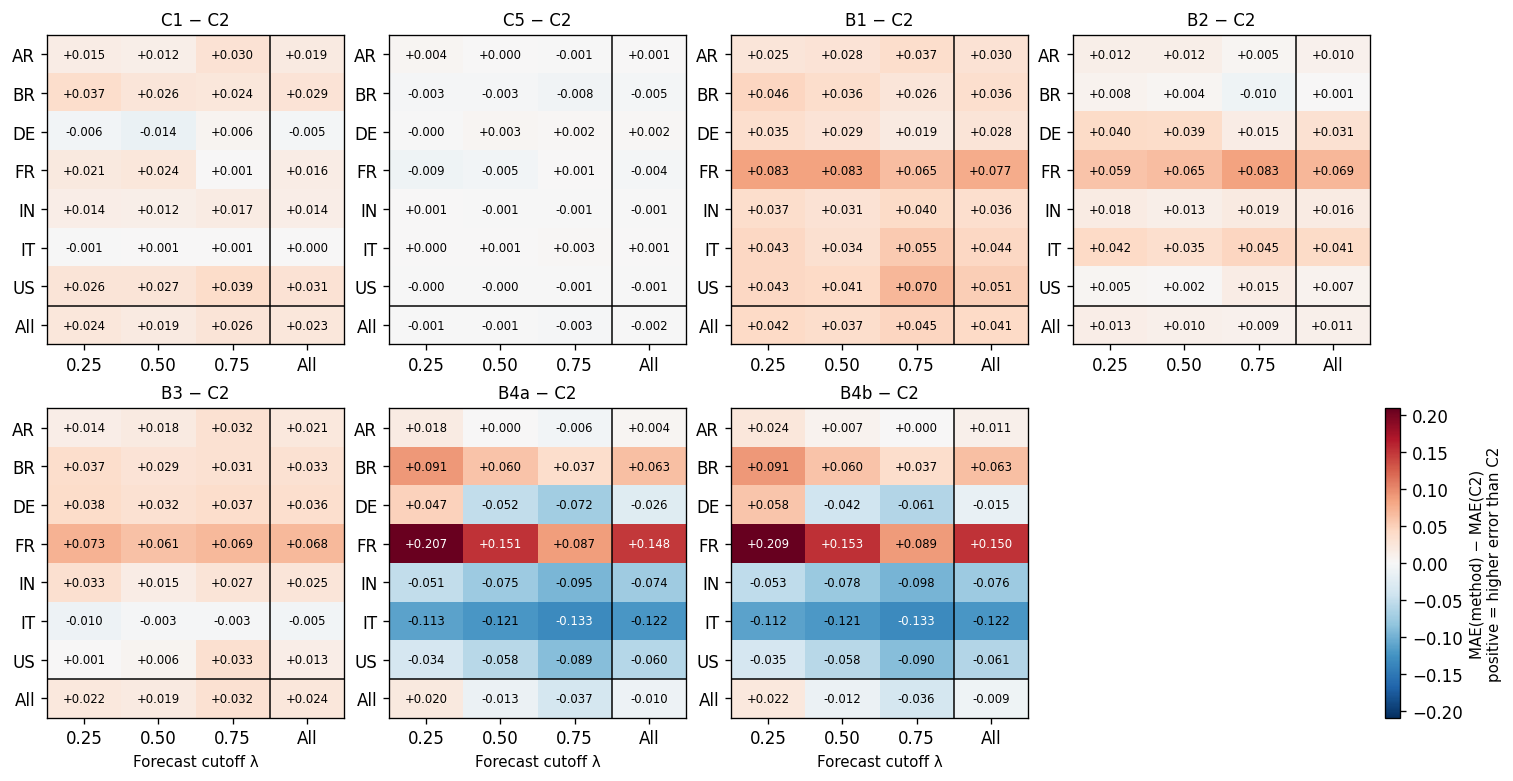

In [39]:
# ===== 6c-3. Country- and cutoff-wise MAE difference heatmap (data and figure for Section 4.1) =====
# MAE(method) - MAE(C2) at the symmetric 1:1 reference on identical held-out forecasts.
# Negative values (blue): lower error than C2. Positive values (red): higher error than C2.
# C3 and C4 are omitted from the figure because they equal C5 to the fourth decimal in the pooled table; the CSV keeps every method.
# Requires: bl_all and tb1 (Section 6b), EXT_PAPER (Section 6c-1), plt (matplotlib.pyplot).
HEAT_REF = 'C2'
HEAT_METHODS = ['C1', 'C5', 'B1', 'B2', 'B3', 'B4a', 'B4b']
_h = bl_all[np.isclose(bl_all.ratio, MAIN_REFERENCE_RATIO)].copy()
_h['abs_error'] = (_h.y_true - _h.y_pred).abs()
_h['cutoff_label'] = _h.cutoff.map(lambda c: f'{c:.2f}')
_agg = dict(MAE=('abs_error', 'mean'), n_forecasts=('abs_error', 'size'))
_cells = _h.groupby(['country', 'cutoff_label', 'method'], as_index=False).agg(**_agg)
_by_country = _h.groupby(['country', 'method'], as_index=False).agg(**_agg).assign(cutoff_label='All')
_by_cutoff = _h.groupby(['cutoff_label', 'method'], as_index=False).agg(**_agg).assign(country='All')
_pooled = _h.groupby('method', as_index=False).agg(**_agg).assign(country='All', cutoff_label='All')
tbE6 = pd.concat([_cells, _by_country, _by_cutoff, _pooled], ignore_index=True)
_ref = tbE6[tbE6.method == HEAT_REF][['country', 'cutoff_label', 'MAE']].rename(columns={'MAE': 'MAE_C2'})
tbE6 = tbE6.merge(_ref, on=['country', 'cutoff_label'], validate='m:1')
tbE6['MAE_diff_vs_C2'] = tbE6.MAE - tbE6.MAE_C2
tbE6 = tbE6.drop(columns='MAE_C2')
# consistency: the pooled cell equals the published pooled MAE of the accuracy table (Table B1)
for _m, _v in tbE6[(tbE6.country == 'All') & (tbE6.cutoff_label == 'All')].set_index('method').MAE.items():
    assert abs(_v - float(tb1.set_index('Method').loc[_m, 'MAE'])) < 1e-12, ('pooled MAE differs from Table B1', _m)
tbE6.to_csv(EXT_PAPER / 'Table_E6_country_cutoff_MAE_difference.csv', index=False)

_cells_only = tbE6[(tbE6.country != 'All') & (tbE6.cutoff_label != 'All') & tbE6.method.isin(HEAT_METHODS)]
wins = (_cells_only.groupby('method').agg(cells=('MAE_diff_vs_C2', 'size'),
        cells_lower_error_than_C2=('MAE_diff_vs_C2', lambda s: int((s < 0).sum())),
        median_MAE_diff=('MAE_diff_vs_C2', 'median'), min_MAE_diff=('MAE_diff_vs_C2', 'min'),
        max_MAE_diff=('MAE_diff_vs_C2', 'max')).reindex(HEAT_METHODS).reset_index())
wins.to_csv(EXT_PAPER / 'Table_E6_summary_cells_lower_than_C2.csv', index=False)
print('Country x cutoff cells in which each method has a lower MAE than C2:'); display(wins.round(4))

_countries = sorted(_h.country.unique()) + ['All']
_cols = [f'{c:.2f}' for c in FRACTIONS] + ['All']
_vmax = float(np.nanmax(np.abs(tbE6[tbE6.method.isin(HEAT_METHODS)].MAE_diff_vs_C2)))
fig, axes = plt.subplots(2, 4, figsize=(12.5, 6.4), constrained_layout=True)
axes = axes.ravel()
for ax, m in zip(axes, HEAT_METHODS):
    mat = (tbE6[tbE6.method == m].pivot(index='country', columns='cutoff_label', values='MAE_diff_vs_C2')
           .reindex(index=_countries, columns=_cols))
    im = ax.imshow(mat.to_numpy(float), cmap='RdBu_r', vmin=-_vmax, vmax=_vmax, aspect='auto')
    ax.set_xticks(range(len(_cols)), _cols); ax.set_yticks(range(len(_countries)), _countries)
    for i in range(len(_countries)):
        for j in range(len(_cols)):
            v = mat.iloc[i, j]
            ax.text(j, i, f'{v:+.3f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(v) > 0.6 * _vmax else 'black')
    ax.axhline(len(_countries) - 1.5, color='k', lw=.9); ax.axvline(len(_cols) - 1.5, color='k', lw=.9)
    ax.set_title(f'{m} − {HEAT_REF}', fontsize=10)
for ax in axes[4:7]:
    ax.set_xlabel('Forecast cutoff λ')
axes[7].axis('off')
fig.colorbar(im, ax=axes[7], fraction=.55, label=f'MAE(method) − MAE({HEAT_REF})\npositive = higher error than {HEAT_REF}')
fig.savefig(EXT_PAPER / 'Figure_E3_MAE_difference_heatmap.png', dpi=200, bbox_inches='tight')
fig.savefig(EXT_PAPER / 'Figure_E3_MAE_difference_heatmap.pdf', bbox_inches='tight')
plt.show(); plt.close(fig)

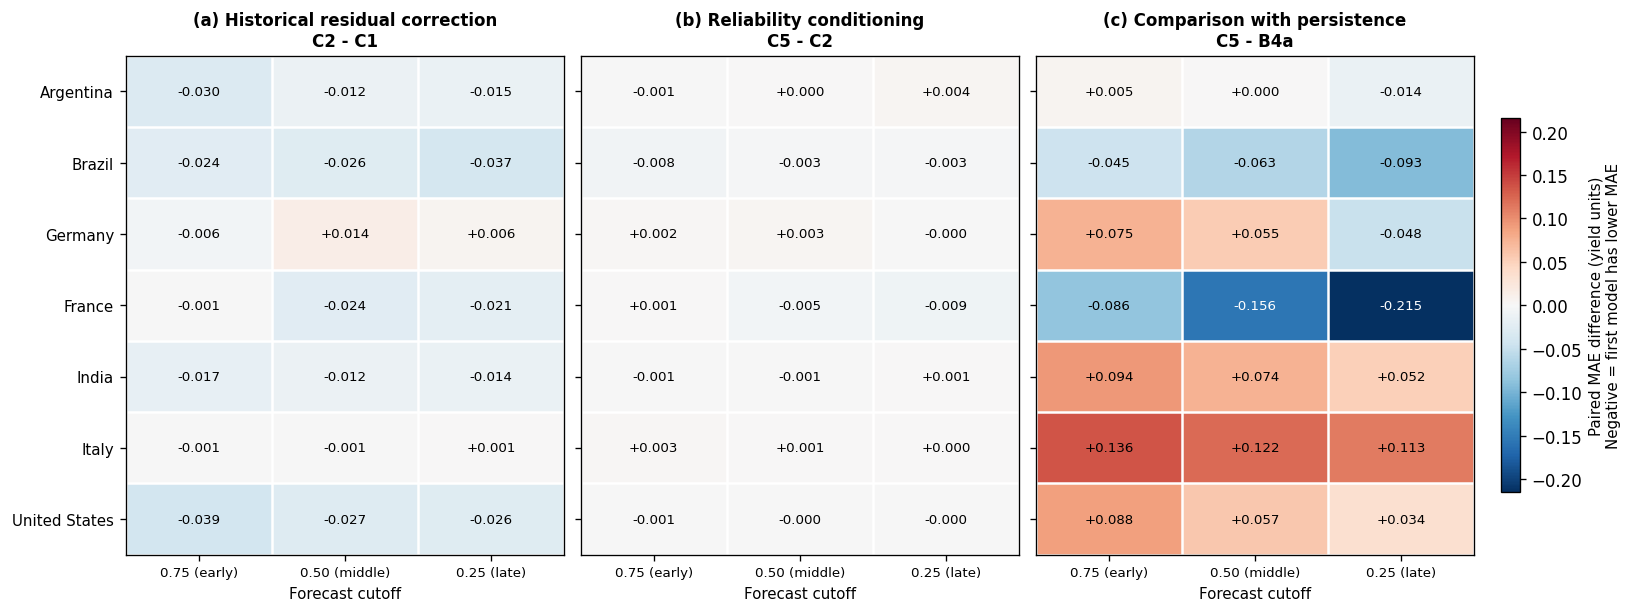

Saved figure and numerical table to: /kaggle/working/cybench_final/Baselines/Baseline Evidence/Supplementary Figures
      country  cutoff  C2 - C1  C5 - C2  C5 - B4a
    Argentina    0.25  -0.0149   0.0036   -0.0140
    Argentina    0.50  -0.0120   0.0003    0.0003
    Argentina    0.75  -0.0296  -0.0009    0.0055
       Brazil    0.25  -0.0373  -0.0027   -0.0935
       Brazil    0.50  -0.0258  -0.0030   -0.0632
       Brazil    0.75  -0.0243  -0.0081   -0.0453
      Germany    0.25   0.0063  -0.0002   -0.0476
      Germany    0.50   0.0137   0.0035    0.0554
      Germany    0.75  -0.0058   0.0023    0.0745
       France    0.25  -0.0211  -0.0086   -0.2154
       France    0.50  -0.0242  -0.0053   -0.1561
       France    0.75  -0.0014   0.0010   -0.0856
        India    0.25  -0.0137   0.0007    0.0517
        India    0.50  -0.0123  -0.0010    0.0744
        India    0.75  -0.0173  -0.0014    0.0938
        Italy    0.25   0.0012   0.0000    0.1126
        Italy    0.50  -0.0010   

In [40]:

# Supplementary figure: Country- and cutoff-wise paired MAE differences
# Uses the completed held-out forecasts from Cell 6b-4.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm

FIG_DIR = Path(BL_PAPER) / "Supplementary Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Symmetric cost setting: MAE equals mean decision loss.
data = bl_all.loc[
    np.isclose(bl_all["ratio"], 1.0)
    & bl_all["method"].isin(["C1", "C2", "C5", "B4a"])
].copy()

keys = ["country", "cutoff", "year", "adm_id"]

assert not data.duplicated(keys + ["method"]).any()

data["abs_error"] = np.abs(
    data["y_true"] - data["y_pred"]
)

# Match predictions for the same country, cutoff, year and region.
paired = data.pivot(
    index=keys,
    columns="method",
    values="abs_error"
)

models = ["C1", "C2", "C5", "B4a"]

assert set(models).issubset(paired.columns)
assert paired[models].notna().all().all(), \
    "Some methods have unmatched held-out observations."

# Preserve the same held-out support for every comparison.
paired = paired[models].reset_index()

# Paired differences calculated at individual forecast level.
comparisons = {
    "C2 - C1": ("C2", "C1"),
    "C5 - C2": ("C5", "C2"),
    "C5 - B4a": ("C5", "B4a")
}

for name, (model_a, model_b) in comparisons.items():
    paired[name] = paired[model_a] - paired[model_b]

# Mean paired differences by country and forecast cutoff.
heatmap_data = (
    paired.groupby(["country", "cutoff"], as_index=False)
    [list(comparisons)]
    .mean()
)

# Save the exact numerical values.
heatmap_data.to_csv(
    FIG_DIR / "Table_S_country_cutoff_MAE_differences.csv",
    index=False
)

# Consistent country ordering.
countries = [
    "Argentina", "Brazil", "Germany", "France",
    "India", "Italy", "United States"
]

# Handle either country names or CY-Bench country codes.
country_codes = {
    "AR": "Argentina",
    "BR": "Brazil",
    "DE": "Germany",
    "FR": "France",
    "IN": "India",
    "IT": "Italy",
    "US": "United States"
}

heatmap_data["country"] = (
    heatmap_data["country"]
    .replace(country_codes)
)

cutoffs = [0.75, 0.50, 0.25]
cutoff_labels = [
    "0.75 (early)",
    "0.50 (middle)",
    "0.25 (late)"
]

# Prepare matrices.
matrices = []

for comparison in comparisons:
    matrix = heatmap_data.pivot(
        index="country",
        columns="cutoff",
        values=comparison
    ).reindex(index=countries, columns=cutoffs)

    matrices.append(matrix)

# Use one common symmetric scale for all panels.
max_abs = max(
    np.nanmax(np.abs(m.to_numpy(dtype=float)))
    for m in matrices
)

if max_abs == 0:
    max_abs = 1e-6

norm = TwoSlopeNorm(
    vmin=-max_abs,
    vcenter=0,
    vmax=max_abs
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600
})

fig, axes = plt.subplots(
    1, 3, figsize=(13.5, 5),
    sharey=True,
    constrained_layout=True
)

panel_titles = [
    "(a) Historical residual correction",
    "(b) Reliability conditioning",
    "(c) Comparison with persistence"
]

for ax, matrix, title, comparison in zip(
    axes, matrices, panel_titles, comparisons
):
    values = matrix.to_numpy(dtype=float)

    im = ax.imshow(
        values,
        cmap="RdBu_r",
        norm=norm,
        aspect="auto"
    )

    ax.set_title(
        f"{title}\n{comparison}",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_xticks(range(len(cutoffs)))
    ax.set_xticklabels(cutoff_labels, fontsize=8)

    ax.set_yticks(range(len(countries)))
    ax.set_yticklabels(countries, fontsize=9)

    ax.set_xlabel("Forecast cutoff")

    # Cell annotations.
    for i in range(len(countries)):
        for j in range(len(cutoffs)):
            value = values[i, j]

            if np.isfinite(value):
                color = (
                    "white"
                    if abs(value) > 0.65 * max_abs
                    else "black"
                )

                ax.text(
                    j, i, f"{value:+.3f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=color
                )
            else:
                ax.text(
                    j, i, "NA",
                    ha="center",
                    va="center",
                    fontsize=8
                )

    ax.set_xticks(
        np.arange(-0.5, len(cutoffs), 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, len(countries), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linewidth=1.5
    )
    ax.tick_params(which="minor", length=0)

# Shared colorbar.
cbar = fig.colorbar(
    im, ax=axes,
    shrink=0.75,
    pad=0.02
)

cbar.set_label(
    "Paired MAE difference (yield units)\n"
    "Negative = first model has lower MAE"
)

# Publication files.
filename = FIG_DIR / "Fig_S_country_cutoff_MAE_heatmap"

for ext in ["pdf", "svg", "png"]:
    fig.savefig(
        f"{filename}.{ext}",
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

print("Saved figure and numerical table to:", FIG_DIR)
print(heatmap_data.round(4).to_string(index=False))
